**Grupo GI** — Projeto de detecção de fraturas ósseas

# CNN para Detecção de Fraturas em Imagens de Ossos

>  **AVISO IMPORTANTE — PROJETO EDUCACIONAL/EXPERIMENTAL**
>
> Este notebook foi criado **para estudo de Machine Learning e Deep Learning**. Os resultados **não devem ser utilizados isoladamente para diagnóstico médico ou tomada de decisão clínica**. Um modelo treinado em um dataset público, sem validação clínica, revisão de especialistas e avaliação em dados externos, **não é um dispositivo médico**. Qualquer interpretação de imagens radiográficas deve ser feita por profissional de saúde habilitado.

```text
Objetivo:
Desenvolver uma rede neural convolucional (CNN) capaz de classificar imagens
de ossos em duas categorias:

0 - Sem fratura
1 - Fratura
```

O modelo **aprende padrões visuais** presentes nas imagens do dataset (bordas, contornos, texturas, descontinuidades no osso etc.) a partir de exemplos rotulados. Ele não "entende" anatomia nem medicina: apenas ajusta seus pesos para associar padrões de pixels a um dos dois rótulos.

---

### Como usar este notebook no Google Colab

1. **Ative a GPU:** menu *Ambiente de execução → Alterar tipo de ambiente de execução → GPU (T4)*.
2. **Organize o dataset no Google Drive** conforme a seção 5.
3. **Ajuste o caminho do dataset** na célula `CONFIGURAÇÃO DO DATASET` (seção 4).
4. Execute as células **em ordem** (*Ambiente de execução → Executar tudo*, ou uma a uma para acompanhar cada etapa).

### Parâmetros que você pode alterar (⚙️)

| Parâmetro | Onde está | Valor inicial |
| --- | --- | --- |
| Caminho do dataset e nomes das classes | Seção 4 | `DATASET_PATH`, `CLASS_NAMES` |
| Semente aleatória (reprodutibilidade) | Seção 3 | `SEED = 42` |
| Tamanho das imagens | Seção 8 | `224 × 224` |
| Batch size | Seção 10 | `32` |
| Número de épocas | Seção 14 | `EPOCHS = 20` |
| Threshold de decisão | Seção 18 | `THRESHOLD = 0.5` |
| Caminho para salvar o modelo | Seção 30 | `MODEL_PATH` |
| Imagem nova para testar | Seção 32 | `NEW_IMAGE_PATH` |
| Transfer Learning (ligar/desligar) | Seção 33 | `RUN_TRANSFER_LEARNING` |

Todas as células com parâmetros ajustáveis são marcadas com **⚙️**.

## 1. Objetivo

O objetivo deste projeto **não é apenas treinar uma CNN**, e sim percorrer todas as etapas de um projeto de Deep Learning para que você compreenda:

1. Como as imagens são **carregadas**;
2. Como o dataset está **organizado**;
3. Como as imagens são **visualizadas**;
4. Como as imagens são **pré-processadas**;
5. Como a **CNN funciona**;
6. Como o modelo é **treinado**;
7. Como acompanhar **Loss** e **Accuracy**;
8. Como **avaliar** o modelo;
9. Como interpretar a **matriz de confusão**;
10. Como calcular **Precision, Recall e F1-Score**;
11. Como visualizar **previsões corretas e incorretas**;
12. Como **salvar** o modelo;
13. Como **utilizar o modelo treinado** para realizar uma nova previsão.

Ao final, também comparamos a CNN construída do zero com uma abordagem de **Transfer Learning** (opcional).

> Lembre-se: a qualidade do resultado depende do dataset. Uma boa métrica **neste** dataset não garante bom desempenho em imagens de outras fontes (veja a seção 35).

## 2. Introdução à CNN

### O que é classificação de imagens?
É a tarefa de receber uma imagem e atribuir **um rótulo (classe)** a ela. Aqui, cada imagem recebe o rótulo *Fratura* ou *Sem fratura*.

### O que é Deep Learning?
É um conjunto de técnicas de Machine Learning baseado em **redes neurais com várias camadas**. Cada camada transforma os dados recebidos em uma representação um pouco mais abstrata. Em imagens, as primeiras camadas tendem a detectar padrões simples (bordas, linhas) e as camadas seguintes combinam esses padrões em estruturas mais complexas (formas, texturas).

### O que é uma CNN (Convolutional Neural Network)?
É uma rede neural especializada em dados com estrutura de grade, como imagens. Em vez de tratar cada pixel de forma isolada, ela examina **pequenas regiões** da imagem com filtros que "deslizam" sobre ela.

### Por que CNNs são usadas para imagens?
* **Aproveitam a vizinhança:** pixels próximos têm relação entre si (uma borda é formada por vários pixels vizinhos).
* **Compartilham pesos:** o mesmo filtro é aplicado em toda a imagem, o que reduz enormemente o número de parâmetros em comparação a uma rede totalmente conectada.
* **Detectam padrões em qualquer posição:** um padrão aprendido em um canto da imagem pode ser reconhecido em outro.

### O que são filtros (convoluções)?
Um filtro (ou *kernel*) é uma pequena matriz de números (por exemplo, 3×3). Ele desliza pela imagem e, em cada posição, multiplica seus valores pelos pixels da região e soma o resultado. Os valores do filtro **são aprendidos durante o treinamento**.

```text
Região 3x3 da imagem      Filtro 3x3 (aprendido)
[ 10  10  200 ]            [ -1  0  1 ]
[ 10  10  200 ]     ×      [ -1  0  1 ]     →   um único número (soma dos produtos)
[ 10  10  200 ]            [ -1  0  1 ]
```
Esse filtro de exemplo responderia com valor alto a uma **borda vertical** (escuro à esquerda, claro à direita).

### O que são mapas de características (feature maps)?
É o resultado de aplicar um filtro à imagem inteira. Cada filtro gera um mapa que mostra **onde** aquele padrão aparece. Uma camada `Conv2D(32, ...)` produz 32 mapas de características.

### O que é pooling?
É uma operação que **reduz a resolução** dos mapas de características. No `MaxPooling2D` (2×2), cada bloco de 4 valores é substituído pelo maior deles. Isso diminui o custo computacional e torna a rede menos sensível a pequenas variações de posição.

### O que são camadas densas (Dense)?
São camadas em que cada neurônio recebe **todas** as entradas da camada anterior. Após extrair características com convoluções, as camadas densas **combinam** essas características para tomar a decisão final.

### O que significa classificação binária?
Existem apenas **duas classes**. A rede produz um único número entre 0 e 1 (via função sigmoid). Com um limiar (*threshold*) de 0,5:

```text
saída >= 0.5  →  classe 1 (Fratura)
saída <  0.5  →  classe 0 (Sem fratura)
```

### Fluxo geral da CNN deste projeto

```text
Imagem
   ↓
Pré-processamento
   ↓
Convolução
   ↓
Feature Maps
   ↓
Pooling
   ↓
Convolução
   ↓
Pooling
   ↓
Flatten
   ↓
Dense
   ↓
Sigmoid
   ↓
Fratura / Sem fratura
```

## 3. Importação das bibliotecas

| Biblioteca | Finalidade |
| --- | --- |
| `os`, `random` | Manipular pastas/arquivos e gerar sorteios reprodutíveis |
| `numpy` | Operações numéricas com arrays (as imagens são arrays) |
| `pandas` | Tabelas (contagem de imagens, resultados, comparação de modelos) |
| `matplotlib` e `seaborn` | Gráficos e visualização de imagens |
| `tensorflow` e `keras` | Construção, treinamento e uso da rede neural |
| `sklearn.metrics` | Métricas de avaliação (matriz de confusão, Precision, Recall, F1, ROC/AUC) |

Também definimos uma **semente aleatória (`SEED`)** para que os sorteios e a inicialização da rede sejam o mais reprodutíveis possível. Note que, mesmo com semente fixa, execuções em GPU podem apresentar pequenas diferenças numéricas.

In [ ]:
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential

# ImageDataGenerator é a abordagem "antiga" de carregar imagens.
# Neste notebook usamos image_dataset_from_directory (mais moderno);
# o import é mantido apenas como referência e protegido contra versões sem ele.
try:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except ImportError:
    ImageDataGenerator = None

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")

# ⚙️ SEMENTE ALEATÓRIA (reprodutibilidade)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"\n✅ GPU disponível: {[g.name for g in gpus]}")
else:
    print("\n⚠️ Nenhuma GPU detectada. O treinamento funcionará, mas será bem mais lento.")
    print("   Ative em: Ambiente de execução → Alterar tipo de ambiente de execução → GPU")

TensorFlow: 2.20.0
Keras: 3.13.2
NumPy: 2.1.3
Pandas: 2.2.3

✅ GPU disponível: ['/physical_device:GPU:0']


## 4. Configuração do Google Drive

O Colab executa em uma máquina virtual temporária. Para acessar o dataset (e salvar o modelo depois), **montamos o Google Drive**. Ao executar a célula abaixo, o Colab abrirá uma janela pedindo autorização para acessar o seu Drive.

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("⚠️ google.colab não encontrado: você não está no Google Colab.")
    print("   Se estiver rodando localmente, apenas ajuste DATASET_PATH abaixo para uma pasta local.")

Mounted at /content/drive


### Configuração do dataset

Na célula seguinte você informa **onde está o dataset** e **como as pastas/classes se chamam**.

> ❗ O caminho `SEU_DATASET` é apenas um exemplo. **Você precisa ajustá-lo** para a pasta real do seu Drive.
> Dica: no painel lateral do Colab (ícone de pasta), navegue até `drive/MyDrive/...`, clique com o botão direito na pasta do dataset e escolha *Copiar caminho*.

**Ordem das classes:** a rede tem uma única saída (sigmoid) que representa a **probabilidade da classe 1**. Por isso a **classe positiva (Fratura) deve ser o índice 1** em `CLASS_NAMES`:

```text
CLASS_NAMES = ["not_fractured", "fractured"]
                    ↑ índice 0        ↑ índice 1
```

> ⚠️ Por padrão o Keras ordena as pastas em **ordem alfabética**, e `fractured` viria *antes* de `not_fractured` (ficaria com o índice 0, o inverso do que queremos). Por isso, mais adiante, passamos `class_names=CLASS_NAMES` de forma explícita ao carregar os dados.

In [ ]:
# ============================================================
#              CONFIGURAÇÃO DO DATASET   ⚙️
#         (ALTERE AQUI O CAMINHO E OS NOMES DAS PASTAS)
# ============================================================

DATASET_PATH = '/content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/'

# Nomes das subpastas de divisão do dataset
TRAIN_FOLDER      = 'train'
VALIDATION_FOLDER = 'validation'
TEST_FOLDER       = 'test'

# Nomes das pastas de cada classe (a POSITIVA - fratura - deve ser a última, índice 1)
CLASS_NAMES = [
    "not fractured",   # índice 0 -> Sem fratura
    "fractured"        # índice 1 -> Fratura
]

# Nomes amigáveis para gráficos e textos (mesma ordem de CLASS_NAMES)
DISPLAY_NAMES = ["Sem fratura", "Fraturado"]

# ------------------------------------------------------------
# Ajuda: mostra o que existe no caminho informado
# ------------------------------------------------------------
if os.path.exists(DATASET_PATH):
    print("Conteúdo de DATASET_PATH:")
    for item in sorted(os.listdir(DATASET_PATH)):
        print("  -", item)
else:
    print(f"⚠️ O caminho não existe: {DATASET_PATH}")
    print("   Ajuste DATASET_PATH nesta célula antes de continuar.")

Conteúdo de DATASET_PATH:
  - test
  - train
  - validation


## 5. Estrutura do dataset

A função `image_dataset_from_directory` do Keras usa o **nome das subpastas como rótulo** das imagens. A estrutura recomendada é:

```text
dataset/
│
├── train/
│   ├── fractured/
│   └── not_fractured/
│
├── validation/
│   ├── fractured/
│   └── not_fractured/
│
└── test/
    ├── fractured/
    └── not_fractured/
```

Os três conjuntos têm papéis diferentes:

| Conjunto | Para que serve |
| --- | --- |
| **Treino (train)** | A rede ajusta seus pesos com essas imagens |
| **Validação (validation)** | Acompanha o desempenho **durante** o treino e decide quando parar (Early Stopping) |
| **Teste (test)** | Avaliação final, com imagens que a rede **nunca usou** para aprender ou ajustar decisões |

Se seus nomes de pasta forem diferentes (por exemplo, `Fracture`/`Normal`), basta alterar as variáveis da seção anterior.

### E se eu não tiver uma pasta "test"?

É comum um dataset vir apenas com `train/` e `validation/`. Sem um conjunto de teste **separado e nunca visto durante o treino**, a avaliação final fica menos confiável (você acabaria avaliando em imagens que, direta ou indiretamente, influenciaram o treinamento).

Por isso, o notebook detecta automaticamente se a pasta `test/` existe:

* **Se existir:** é usada normalmente, como nas seções seguintes.
* **Se não existir:** o notebook pode **separar uma fração de `train/` (ou de `validation/`) para servir como teste**, de forma estratificada (mesma proporção em cada classe) e com semente fixa (reprodutível). Isso é controlado pelos parâmetros abaixo.

> ⚠️ Retirar o teste do **treino** é a opção recomendada, pois a validação já tem um papel importante durante o treinamento (Early Stopping). Reduzi-la também é possível, mas deixa menos imagens para monitorar o treino.
> Essa divisão é feita **uma vez**, antes de qualquer treinamento — as imagens sorteadas para teste não entram no treino nem na validação.

In [ ]:
# ============================================================
#   CONFIGURAÇÃO DO CONJUNTO DE TESTE (CASO NÃO EXISTA)   ⚙️
# ============================================================

# Se a pasta TEST_FOLDER não existir dentro de DATASET_PATH, criar
# automaticamente um conjunto de teste a partir de outra pasta?
CREATE_TEST_SET_IF_MISSING = True

# De qual pasta tirar as imagens de teste: 'train' ou 'validation'
TEST_SOURCE = 'train'

# Proporção de cada classe reservada para teste (ex.: 0.15 = 15%)
TEST_FRACTION = 0.15

assert TEST_SOURCE in ('train', 'validation'), "TEST_SOURCE deve ser 'train' ou 'validation'"

A célula abaixo **verifica quais pastas existem** e decide se será preciso construir o conjunto de teste.

In [ ]:
train_dir      = os.path.join(DATASET_PATH, TRAIN_FOLDER)
validation_dir = os.path.join(DATASET_PATH, VALIDATION_FOLDER)
test_dir       = os.path.join(DATASET_PATH, TEST_FOLDER)

def _pasta_ok(pasta):
    # Verifica se a pasta existe e se contém todas as subpastas de classe
    if not os.path.exists(pasta):
        return False
    return all(os.path.isdir(os.path.join(pasta, c)) for c in CLASS_NAMES)

for nome, pasta in [("train", train_dir), ("validation", validation_dir), ("test", test_dir)]:
    print(f"{pasta}  ->  ok? {_pasta_ok(pasta)}")
    for c in CLASS_NAMES:
        cd = os.path.join(pasta, c)
        print(f"      {cd}  ->  existe? {os.path.isdir(cd)}")

if not (_pasta_ok(train_dir) and _pasta_ok(validation_dir)):
    raise FileNotFoundError(
        "\n\n❌ As pastas 'train' e/ou 'validation' (com as subpastas de cada classe) não foram encontradas.\n"
        "   Verifique:\n"
        "   1) DATASET_PATH aponta para a pasta correta do seu Google Drive?\n"
        "   2) TRAIN_FOLDER e VALIDATION_FOLDER têm esses nomes?\n"
        "   3) As pastas das classes (CLASS_NAMES) têm exatamente esses nomes?\n"
        "   Corrija a célula 'CONFIGURAÇÃO DO DATASET' (seção 4) e execute novamente."
    )

PRECISA_CRIAR_TESTE = not _pasta_ok(test_dir)

if PRECISA_CRIAR_TESTE:
    if not CREATE_TEST_SET_IF_MISSING:
        raise FileNotFoundError(
            "\n\n❌ A pasta 'test' não foi encontrada e CREATE_TEST_SET_IF_MISSING está desativado.\n"
            "   Ative CREATE_TEST_SET_IF_MISSING na célula acima, ou crie a pasta 'test' manualmente no seu Drive."
        )
    print(f"\n⚠️ Pasta 'test' não encontrada. Será criada automaticamente a partir de '{TEST_SOURCE}' "
          f"(próxima célula), reservando {TEST_FRACTION:.0%} de cada classe.")
else:
    print("\n✅ Estrutura completa do dataset encontrada (train, validation e test).")

/content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/train  ->  ok? True
      /content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/train/not fractured  ->  existe? True
      /content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/train/fractured  ->  existe? True
/content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/validation  ->  ok? True
      /content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/validation/not fractured  ->  existe? True
      /content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/validation/fractured  ->  existe? True
/content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/test  ->  ok? False
      /content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/test/not fractured  ->  existe? False
      /content/drive/MyDrive/Projeto Final/DataSet Raio-x/dataset/test/fractured  ->  existe? False

⚠️ Pasta 'test' não encontrada. Será criada automaticamente a partir de 'train' (próxima célula), reservando 15% de cada classe.


### Materialização do dataset (e criação do teste, se necessário)

Esta célula faz uma de duas coisas:

* **Se a pasta `test/` já existia:** apenas copia (opcionalmente) train/validation/test para o disco local do Colab, o que costuma acelerar bastante o treinamento em relação a ler direto do Drive.
* **Se a pasta `test/` precisa ser criada:** separa, de forma **estratificada por classe** e com semente fixa, `TEST_FRACTION` das imagens de `TEST_SOURCE` para um novo conjunto de teste local, e copia o restante (train, validation e a fonte já sem o holdout) também para o disco local. As imagens sorteadas para teste **saem** do conjunto de origem — não são usadas duas vezes.

Em ambos os casos, a cópia é **temporária** (some quando a sessão do Colab termina) e o dataset original no Drive **não é alterado** (só lemos os arquivos; nada é apagado ou movido lá).

In [ ]:
import shutil

LOCAL_DATASET_PATH = '/content/dataset_local'

IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png', '.bmp', '.gif')

def listar_imagens(pasta_classe):
    # Retorna a lista ordenada de caminhos de imagens de uma pasta de classe
    return sorted(
        os.path.join(pasta_classe, f)
        for f in os.listdir(pasta_classe)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    )

def _copiar_pasta_classe(origem, destino):
    os.makedirs(destino, exist_ok=True)
    for arquivo in listar_imagens(origem):
        shutil.copy2(arquivo, destino)

def _copiar_com_holdout(origem, destino_principal, destino_teste, fracao_teste, semente):
    # Copia (1 - fracao_teste) das imagens para destino_principal e o restante para destino_teste
    os.makedirs(destino_principal, exist_ok=True)
    os.makedirs(destino_teste, exist_ok=True)
    arquivos = listar_imagens(origem)
    embaralhados = arquivos[:]
    random.Random(semente).shuffle(embaralhados)
    n_teste = max(1, round(len(embaralhados) * fracao_teste))
    conjunto_teste = set(embaralhados[:n_teste])
    for arquivo in arquivos:
        destino = destino_teste if arquivo in conjunto_teste else destino_principal
        shutil.copy2(arquivo, destino)
    return len(arquivos) - n_teste, n_teste

t0 = time.time()

if PRECISA_CRIAR_TESTE:
    print(f"Construindo o conjunto de teste a partir de '{TEST_SOURCE}' (pode levar alguns minutos)...")

    origem_split_dir  = train_dir if TEST_SOURCE == 'train' else validation_dir
    outra_pasta_dir   = validation_dir if TEST_SOURCE == 'train' else train_dir

    novo_train_dir      = os.path.join(LOCAL_DATASET_PATH, TRAIN_FOLDER)
    novo_validation_dir = os.path.join(LOCAL_DATASET_PATH, VALIDATION_FOLDER)
    novo_test_dir       = os.path.join(LOCAL_DATASET_PATH, TEST_FOLDER)

    destino_split_dir   = novo_train_dir if TEST_SOURCE == 'train' else novo_validation_dir
    destino_outra_pasta = novo_validation_dir if TEST_SOURCE == 'train' else novo_train_dir

    resumo = []
    for c in CLASS_NAMES:
        n_mantidas, n_teste = _copiar_com_holdout(
            os.path.join(origem_split_dir, c),
            os.path.join(destino_split_dir, c),
            os.path.join(novo_test_dir, c),
            TEST_FRACTION,
            semente=SEED
        )
        _copiar_pasta_classe(os.path.join(outra_pasta_dir, c), os.path.join(destino_outra_pasta, c))
        resumo.append({"Classe": c, f"Mantidas em '{TEST_SOURCE}'": n_mantidas, "Reservadas p/ teste": n_teste})

    train_dir, validation_dir, test_dir = novo_train_dir, novo_validation_dir, novo_test_dir

    print(f"✅ Conjunto de teste criado em {time.time() - t0:.0f} s")
    display(pd.DataFrame(resumo).set_index("Classe"))
    print(f"\nAs imagens reservadas para teste foram retiradas de '{TEST_SOURCE}' — o dataset local "
          "reflete isso; o dataset original no Drive permanece intacto.")

else:
    # ⚙️ Copiar para o disco local do Colab? (mais rápido para treinar)
    COPY_TO_LOCAL = True
    if COPY_TO_LOCAL:
        print("Copiando dataset do Drive para o disco local (pode levar alguns minutos)...")
        for pasta in [TRAIN_FOLDER, VALIDATION_FOLDER, TEST_FOLDER]:
            shutil.copytree(
                os.path.join(DATASET_PATH, pasta),
                os.path.join(LOCAL_DATASET_PATH, pasta),
                dirs_exist_ok=True
            )
        train_dir      = os.path.join(LOCAL_DATASET_PATH, TRAIN_FOLDER)
        validation_dir = os.path.join(LOCAL_DATASET_PATH, VALIDATION_FOLDER)
        test_dir       = os.path.join(LOCAL_DATASET_PATH, TEST_FOLDER)
        print(f"✅ Cópia concluída em {time.time() - t0:.0f} s")
    else:
        print("Usando os arquivos diretamente do Google Drive.")

print("\nPastas em uso:")
print("  train      :", train_dir)
print("  validation :", validation_dir)
print("  test       :", test_dir)

Construindo o conjunto de teste a partir de 'train' (pode levar alguns minutos)...
✅ Conjunto de teste criado em 237 s


,Mantidas em 'train',Reservadas p/ teste
Classe,,
not fractured,3726,657
fractured,3808,672



As imagens reservadas para teste foram retiradas de 'train' — o dataset local reflete isso; o dataset original no Drive permanece intacto.

Pastas em uso:
  train      : /content/dataset_local/train
  validation : /content/dataset_local/validation
  test       : /content/dataset_local/test


## 6. Análise quantitativa do dataset

Antes de treinar, é essencial saber **quantas imagens** existem em cada conjunto e em cada classe.

A função `listar_imagens`, já criada na seção anterior, é reaproveitada aqui para contar os arquivos de cada pasta de classe.

Quantidade de imagens por conjunto e classe:


,Sem fratura,Fraturado,Total
Treino,3726,3808,7534
Validação,240,360,600
Teste,657,672,1329



Proporção entre as classes (%):


,% Sem fratura,% Fraturado
Treino,49.5,50.5
Validação,40.0,60.0
Teste,49.4,50.6


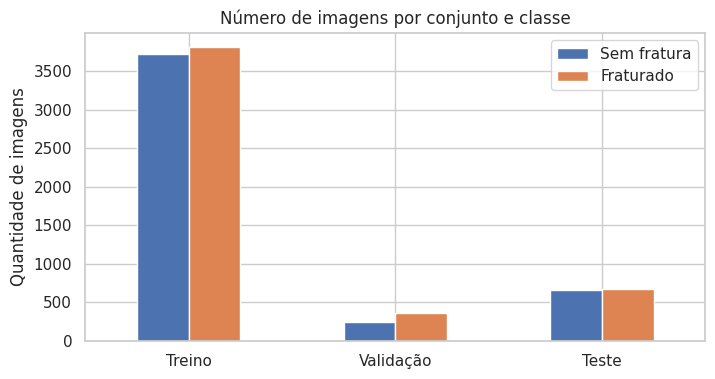


No treino: 3726 'Sem fratura' vs 3808 'Fraturado' (razão maior/menor = 1.02) -> aproximadamente BALANCEADO


In [ ]:
splits = [("Treino", train_dir), ("Validação", validation_dir), ("Teste", test_dir)]

# counts[conjunto][nome_da_pasta_da_classe] = quantidade de imagens
counts = {
    nome: {c: len(listar_imagens(os.path.join(pasta, c))) for c in CLASS_NAMES}
    for nome, pasta in splits
}

# Tabela de contagem
df_counts = pd.DataFrame(counts).T[CLASS_NAMES]
df_counts.columns = DISPLAY_NAMES
df_counts["Total"] = df_counts.sum(axis=1)

print("Quantidade de imagens por conjunto e classe:")
display(df_counts)

# Proporção entre as classes em cada conjunto
df_prop = pd.DataFrame({
    f"% {DISPLAY_NAMES[0]}": (df_counts[DISPLAY_NAMES[0]] / df_counts["Total"] * 100).round(1),
    f"% {DISPLAY_NAMES[1]}": (df_counts[DISPLAY_NAMES[1]] / df_counts["Total"] * 100).round(1),
})
print("\nProporção entre as classes (%):")
display(df_prop)

# Gráfico
df_counts[DISPLAY_NAMES].plot(kind="bar", figsize=(8, 4), rot=0)
plt.title("Número de imagens por conjunto e classe")
plt.ylabel("Quantidade de imagens")
plt.show()

# Diagnóstico automático do balanceamento (no conjunto de treino)
n_neg, n_pos = df_counts.loc["Treino", DISPLAY_NAMES[0]], df_counts.loc["Treino", DISPLAY_NAMES[1]]
razao = max(n_neg, n_pos) / max(min(n_neg, n_pos), 1)
if razao < 1.2:
    nivel = "aproximadamente BALANCEADO"
elif razao < 2:
    nivel = "moderadamente DESBALANCEADO"
else:
    nivel = "fortemente DESBALANCEADO"
print(f"\nNo treino: {n_neg} '{DISPLAY_NAMES[0]}' vs {n_pos} '{DISPLAY_NAMES[1]}' "
      f"(razão maior/menor = {razao:.2f}) -> {nivel}")

# Guardamos as contagens de treino (usadas depois para class_weight)
train_counts = counts["Treino"]

### Dataset balanceado × desbalanceado

```text
Dataset balanceado     → as classes têm quantidades parecidas de imagens.
Dataset desbalanceado  → uma classe tem muito mais imagens que a outra.
```

Isso importa porque **um dataset muito desbalanceado pode gerar uma Accuracy aparentemente alta mesmo com desempenho ruim em uma das classes**. Exemplo extremo: se 90% das imagens forem "Sem fratura", um modelo que responda *sempre* "Sem fratura" já teria 90% de Accuracy — mas **nunca identificaria uma fratura**.

Por isso, além da Accuracy, este notebook analisa **Precision, Recall, F1-Score, matriz de confusão e curvas ROC/Precision-Recall**. Existe ainda a opção de usar `class_weight` no treino (seção 14) para dar mais peso à classe minoritária.

### (Opcional) Verificação de imagens duplicadas ⚙️

Se a mesma imagem (ou uma cópia idêntica) aparecer no treino **e** no teste, o modelo estará sendo avaliado em algo que já "viu", e as métricas ficam artificialmente otimistas (*data leakage*). A célula abaixo compara o **hash MD5 do conteúdo dos arquivos** para detectar cópias **exatamente idênticas**. Ela é opcional (`False` por padrão) porque pode demorar em datasets grandes. Ela **não detecta** imagens apenas *parecidas* (recortadas, redimensionadas, etc.).

In [ ]:
# ⚙️ Verificar duplicatas exatas entre os conjuntos? (pode demorar)
CHECK_DUPLICATES = False

if CHECK_DUPLICATES:
    import hashlib
    from collections import defaultdict

    hashes = defaultdict(list)
    for nome, pasta in splits:
        for c in CLASS_NAMES:
            for p in listar_imagens(os.path.join(pasta, c)):
                with open(p, "rb") as f:
                    h = hashlib.md5(f.read()).hexdigest()
                hashes[h].append((nome, c, p))

    duplicadas  = {h: v for h, v in hashes.items() if len(v) > 1}
    entre_splits = {h: v for h, v in duplicadas.items() if len({s for s, _, _ in v}) > 1}
    rotulos_conflitantes = {h: v for h, v in duplicadas.items() if len({c for _, c, _ in v}) > 1}

    print(f"Grupos de arquivos idênticos: {len(duplicadas)}")
    print(f"  ...que aparecem em conjuntos diferentes (possível vazamento): {len(entre_splits)}")
    print(f"  ...com rótulos diferentes para a mesma imagem: {len(rotulos_conflitantes)}")
else:
    print("Verificação de duplicatas desativada (CHECK_DUPLICATES = False).")

Verificação de duplicatas desativada (CHECK_DUPLICATES = False).


## 7. Visualização das imagens

Antes de treinar, **olhe para os dados**. A inspeção visual ajuda a perceber:

* diferenças de brilho, contraste e enquadramento;
* imagens com texto, marcações ou anotações;
* ossos/regiões diferentes;
* imagens de má qualidade ou possivelmente com rótulo errado.

A célula mostra **16 imagens sorteadas do conjunto de treino** (8 de cada classe), em ordem aleatória.

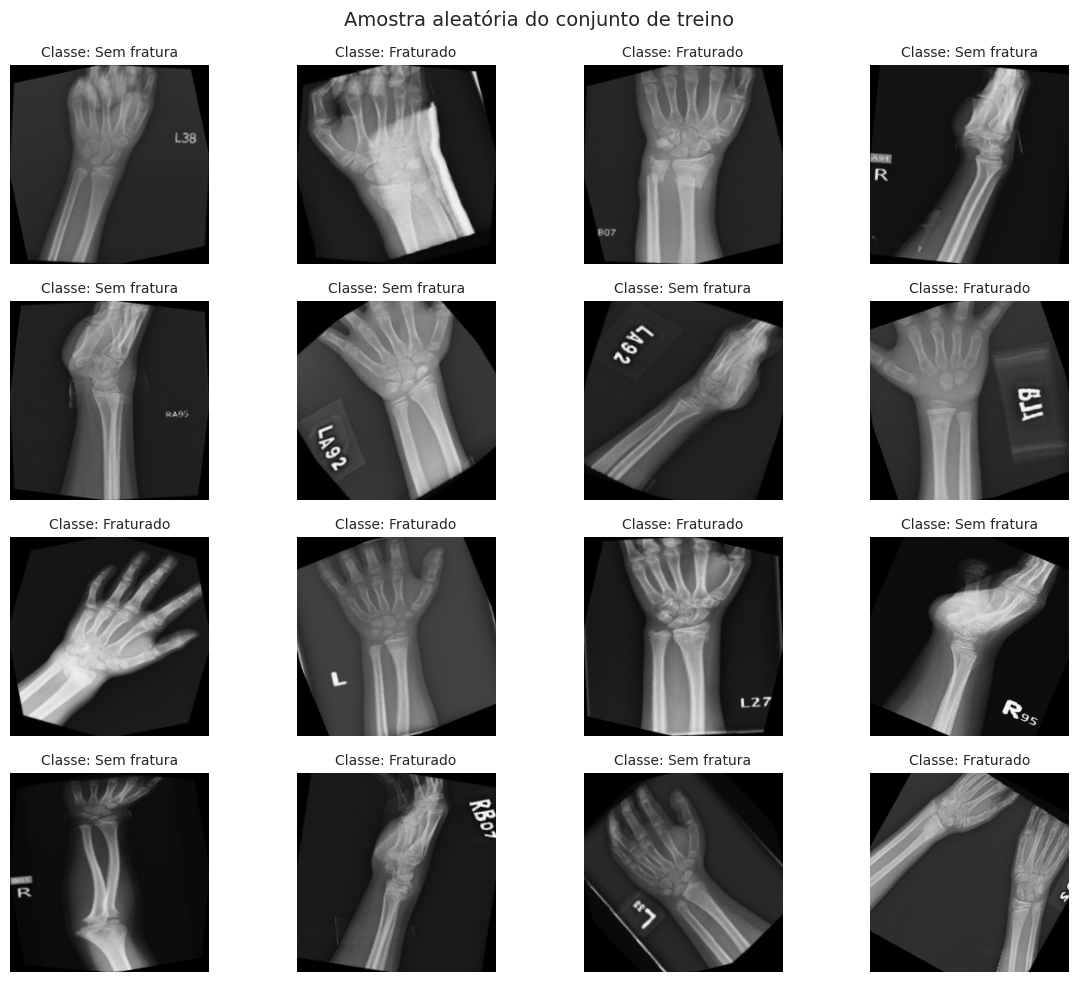

In [ ]:
N_POR_CLASSE = 8
rng = random.Random(SEED)

# Sorteia imagens de cada classe: lista de (caminho, rótulo)
exemplos = []
for label, class_name in enumerate(CLASS_NAMES):
    arquivos = listar_imagens(os.path.join(train_dir, class_name))
    exemplos += [(p, label) for p in rng.sample(arquivos, min(N_POR_CLASSE, len(arquivos)))]
rng.shuffle(exemplos)

plt.figure(figsize=(12, 10))
for i, (caminho, label) in enumerate(exemplos):
    plt.subplot(4, 4, i + 1)
    img = tf.keras.utils.load_img(caminho)   # carrega como imagem RGB
    plt.imshow(img)
    plt.title(f"Classe: {DISPLAY_NAMES[label]}", fontsize=10)
    plt.axis("off")
plt.suptitle("Amostra aleatória do conjunto de treino", fontsize=14)
plt.tight_layout()
plt.show()

## 8. Pré-processamento

Redes neurais precisam receber **entradas com dimensões padronizadas**. Se as imagens do dataset tiverem tamanhos diferentes, todas serão **redimensionadas** para o mesmo tamanho.

### Dimensão das imagens

Definimos inicialmente `224 × 224` pixels. Imagens **maiores** preservam mais detalhes, mas aumentam o custo computacional (memória e tempo de treino); imagens **menores** treinam mais rápido, mas podem perder detalhes finos, como fraturas sutis. `224 × 224` é um bom ponto de partida e é o tamanho padrão de vários modelos pré-treinados (usado no Transfer Learning).

A célula abaixo também **inspeciona uma amostra** do dataset para mostrar os tamanhos originais e o modo de cor (`L` = tons de cinza, `RGB` = colorida).

In [ ]:
# ⚙️ TAMANHO DAS IMAGENS
IMG_HEIGHT = 224
IMG_WIDTH  = 224
IMG_SIZE   = (IMG_HEIGHT, IMG_WIDTH)

# Inspeção de uma amostra (até 100 imagens por classe do treino)
from PIL import Image

amostra = []
for c in CLASS_NAMES:
    arquivos = listar_imagens(os.path.join(train_dir, c))
    amostra += random.Random(SEED).sample(arquivos, min(100, len(arquivos)))

info = []
for p in amostra:
    with Image.open(p) as im:
        info.append({"largura": im.size[0], "altura": im.size[1], "modo": im.mode})
df_info = pd.DataFrame(info)

print(f"Tamanho original das imagens (amostra de {len(df_info)}):")
display(df_info[["largura", "altura"]].describe().loc[["min", "mean", "max"]].round(0))
print("\nModo de cor:")
print(df_info["modo"].value_counts().to_string())
print(f"\nTodas serão redimensionadas para {IMG_WIDTH}x{IMG_HEIGHT} pixels.")
print("Imagens em tons de cinza serão carregadas com 3 canais (o canal é replicado).")

Tamanho original das imagens (amostra de 200):


,largura,altura
min,224.0,224.0
mean,249.0,264.0
max,1500.0,2974.0



Modo de cor:
modo
RGB    195
L        5

Todas serão redimensionadas para 224x224 pixels.
Imagens em tons de cinza serão carregadas com 3 canais (o canal é replicado).


### Normalização dos pixels

Uma imagem em tons de cinza de 8 bits tem pixels com valores de **0 a 255**. Redes neurais treinam melhor com valores em **escala pequena**:

```text
Pixel original:
0 → 255

Após normalização (dividir por 255):
0 → 1
```

**Por que isso ajuda?** Entradas grandes geram ativações e gradientes de grande magnitude, o que pode tornar o treinamento instável e lento. Com entradas entre 0 e 1, a otimização tende a ser mais estável e rápida.

Neste notebook a normalização é feita **dentro do modelo**, pela camada `layers.Rescaling(1./255)`. Vantagem: o modelo salvo já "sabe" normalizar; ao prever uma imagem nova, basta fornecer os pixels originais (0–255). **Não divida por 255 manualmente antes**, senão a normalização será aplicada duas vezes.

A célula abaixo demonstra o efeito em uma imagem.

Imagem: Sem fratura
Formato (altura, largura, canais): (224, 224, 3)
Antes : min = 0.0 | max = 208.0
Depois: min = 0.000 | max = 0.816


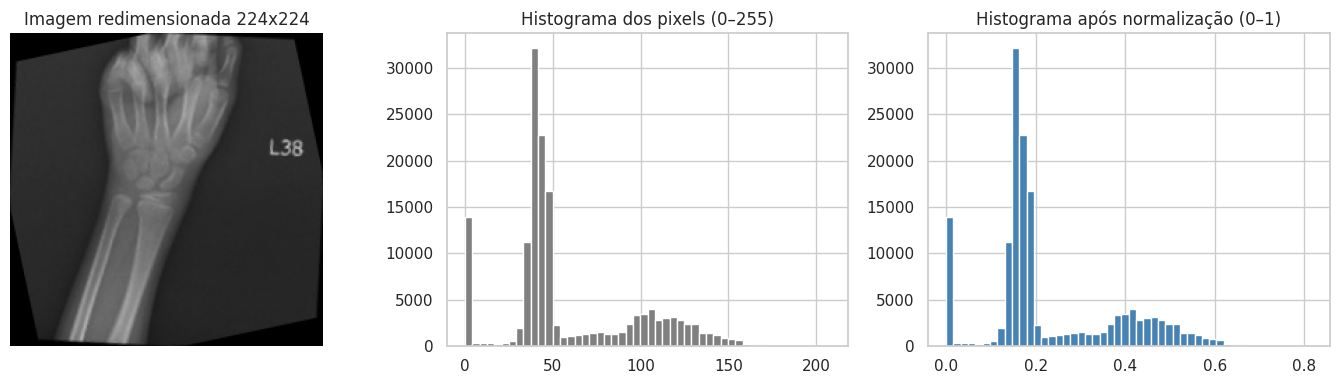

In [ ]:
normalization_layer = layers.Rescaling(1./255)

caminho_exemplo, label_exemplo = exemplos[0]
exemplo = tf.keras.utils.img_to_array(
    tf.keras.utils.load_img(caminho_exemplo, target_size=IMG_SIZE)
)
exemplo_norm = normalization_layer(exemplo).numpy()

print(f"Imagem: {DISPLAY_NAMES[label_exemplo]}")
print(f"Formato (altura, largura, canais): {exemplo.shape}")
print(f"Antes : min = {exemplo.min():.1f} | max = {exemplo.max():.1f}")
print(f"Depois: min = {exemplo_norm.min():.3f} | max = {exemplo_norm.max():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(exemplo.astype("uint8"))
axes[0].set_title(f"Imagem redimensionada {IMG_WIDTH}x{IMG_HEIGHT}")
axes[0].axis("off")
axes[1].hist(exemplo.ravel(), bins=50, color="gray")
axes[1].set_title("Histograma dos pixels (0–255)")
axes[2].hist(exemplo_norm.ravel(), bins=50, color="steelblue")
axes[2].set_title("Histograma após normalização (0–1)")
plt.tight_layout()
plt.show()

## 9. Data Augmentation

O *Data Augmentation* (aumento de dados) aplica **pequenas transformações aleatórias** às imagens **durante o treinamento**. A cada época a rede vê versões ligeiramente diferentes da mesma imagem, o que ajuda a reduzir o **overfitting** (memorização das imagens de treino).

| Transformação | O que faz | Por que pode ajudar |
| --- | --- | --- |
| `RandomFlip("horizontal")` | Espelha a imagem horizontalmente | Torna a rede menos dependente da lateralidade/posição do membro na imagem |
| `RandomRotation(0.05)` | Gira aleatoriamente até ±5% de volta (≈ ±18°) | Simula pequenas diferenças de posicionamento |
| `RandomZoom(0.10)` | Aproxima/afasta até 10% | Simula diferenças de enquadramento/distância |

### Cuidados importantes

* As transformações devem representar **variações plausíveis** das imagens reais. Rotações e zooms exagerados podem deformar ou cortar a região da fratura e **prejudicar** o aprendizado.
* O espelhamento horizontal também inverte eventuais marcadores de lateralidade (letras "L"/"R") presentes na imagem. Se isso for relevante para o seu dataset, remova o `RandomFlip`.
* **Não aplicamos Data Augmentation ao conjunto de teste** (nem ao de validação). As camadas `Random*` do Keras só atuam durante o treinamento (`training=True`); em `evaluate()` e `predict()` elas ficam **inativas**. Por isso colocamos o `data_augmentation` **dentro do modelo**: ele é usado no treino e ignorado na avaliação e nas previsões.

A célula abaixo mostra a imagem original e 8 versões aumentadas.

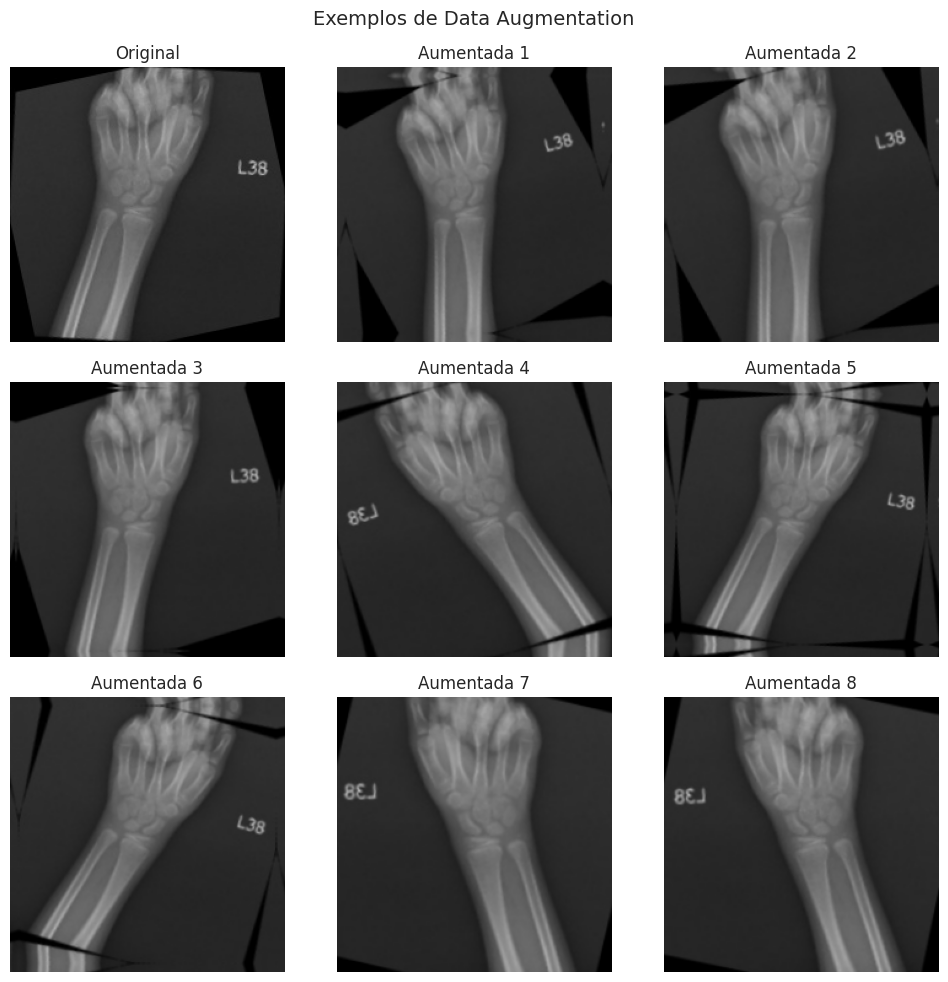

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10)
], name="data_augmentation")

img_aug = tf.keras.utils.img_to_array(
    tf.keras.utils.load_img(exemplos[0][0], target_size=IMG_SIZE)
)
img_aug = tf.expand_dims(img_aug, 0)   # adiciona a dimensão de batch: (1, altura, largura, 3)

plt.figure(figsize=(10, 10))
plt.subplot(3, 3, 1)
plt.imshow(img_aug[0].numpy().astype("uint8"))
plt.title("Original")
plt.axis("off")

for i in range(2, 10):
    aug = data_augmentation(img_aug, training=True)   # training=True ativa as transformações
    plt.subplot(3, 3, i)
    plt.imshow(aug[0].numpy().astype("uint8"))
    plt.title(f"Aumentada {i - 1}")
    plt.axis("off")
plt.suptitle("Exemplos de Data Augmentation", fontsize=14)
plt.tight_layout()
plt.show()

## 10. Criação dos datasets

Usamos `tf.keras.utils.image_dataset_from_directory()`, que:

1. lê as imagens de cada subpasta;
2. usa o **nome da subpasta como rótulo**;
3. redimensiona para `IMG_SIZE`;
4. agrupa as imagens em **lotes (batches)**.

Pontos importantes:

* `label_mode='binary'` → os rótulos são `0.0` ou `1.0`, compatíveis com a saída sigmoid.
* `class_names=CLASS_NAMES` → **fixa** a ordem das classes (0 = Sem fratura, 1 = Fratura), em vez da ordem alfabética padrão.
* `shuffle=True` apenas no **treino** (embaralhar evita que a rede aprenda a ordem das imagens). Validação e teste **não** são embaralhados, para que a ordem das previsões corresponda à ordem dos arquivos (usaremos isso na análise de erros).
* `seed=SEED` → embaralhamento reprodutível.

### Significado do label

```text
label 0.0  →  Sem fratura  (pasta not_fractured)
label 1.0  →  Fratura      (pasta fractured)
```

### `prefetch`

Enquanto a GPU treina com o lote atual, o `prefetch` já **prepara os próximos lotes** em segundo plano, evitando que a GPU fique ociosa esperando dados. `tf.data.AUTOTUNE` deixa o TensorFlow escolher o tamanho do buffer.

In [ ]:
# ⚙️ BATCH SIZE (número de imagens processadas por vez)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    class_names=CLASS_NAMES,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True,
    seed=SEED
)

validation_ds = tf.keras.utils.image_dataset_from_directory(
    validation_dir,
    class_names=CLASS_NAMES,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    class_names=CLASS_NAMES,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=False
)

# Guardamos a lista de arquivos do teste (mesma ordem das previsões, pois shuffle=False)
test_file_paths = list(test_ds.file_paths)

class_names = train_ds.class_names
print("\nClasses (índice = rótulo):", class_names)
for i, nome in enumerate(class_names):
    print(f"   {i} -> {nome}  ({DISPLAY_NAMES[i]})")

# Pipeline de performance
AUTOTUNE = tf.data.AUTOTUNE
train_ds      = train_ds.prefetch(buffer_size=AUTOTUNE)
validation_ds = validation_ds.prefetch(buffer_size=AUTOTUNE)
test_ds       = test_ds.prefetch(buffer_size=AUTOTUNE)

# Inspeciona um lote
for images, labels in train_ds.take(1):
    print("\nUm lote de treino:")
    print("  images:", images.shape, images.dtype, f"| pixels de {float(tf.reduce_min(images)):.0f} a {float(tf.reduce_max(images)):.0f}")
    print("  labels:", labels.shape, labels.dtype, "| exemplo:", labels[:8].numpy().ravel())

Found 7534 files belonging to 2 classes.
Found 600 files belonging to 2 classes.
Found 1329 files belonging to 2 classes.

Classes (índice = rótulo): ['not fractured', 'fractured']
   0 -> not fractured  (Sem fratura)
   1 -> fractured  (Fraturado)

Um lote de treino:
  images: (32, 224, 224, 3) <dtype: 'float32'> | pixels de 0 a 255
  labels: (32, 1) <dtype: 'float32'> | exemplo: [1. 1. 1. 0. 0. 1. 1. 0.]


## 11. Construção da CNN

Vamos construir uma CNN **básica e didática**, do zero. A entrada é uma imagem `224 × 224 × 3` e a saída é **um único número entre 0 e 1**.

O modelo é uma sequência de blocos: **(Conv2D → MaxPooling)** três vezes para extrair características, seguidos de camadas densas para decidir a classe.

```text
Entrada (224x224x3)
   ↓  data_augmentation (só no treino)
   ↓  Rescaling (0–255 → 0–1)
   ↓  Conv2D(32)  + ReLU  → MaxPooling
   ↓  Conv2D(64)  + ReLU  → MaxPooling
   ↓  Conv2D(128) + ReLU  → MaxPooling
   ↓  Flatten
   ↓  Dense(128) + ReLU → Dropout(0.5)
   ↓  Dense(1) + Sigmoid
Saída: probabilidade estimada de Fratura (0 a 1)
```

### Explicando cada componente

#### `Conv2D`
Aplica um conjunto de **filtros** (aqui de tamanho 3×3) deslizando sobre a imagem. `Conv2D(32, (3,3))` aprende **32 filtros diferentes**, produzindo 32 mapas de características. Cada filtro tem 3×3×(canais de entrada) pesos + 1 viés, todos aprendidos no treino. Conforme avançamos nas camadas, o número de filtros aumenta (32 → 64 → 128) porque as camadas mais profundas combinam padrões simples em padrões mais complexos.

#### `ReLU` (`activation='relu'`)
Função de ativação `f(x) = max(0, x)`: zera valores negativos e mantém os positivos. Sem uma função de ativação **não linear**, várias camadas empilhadas seriam equivalentes a uma só operação linear e a rede não conseguiria aprender padrões complexos. A ReLU é simples, rápida e ajuda a evitar o problema do gradiente que desaparece.

#### `MaxPooling2D`
Divide o mapa em blocos 2×2 e mantém **apenas o maior valor** de cada bloco. Reduz a altura e a largura pela metade, diminui o número de cálculos e torna a rede mais tolerante a pequenos deslocamentos dos padrões.

#### `Flatten`
Transforma os mapas de características (um "cubo" `altura × largura × filtros`) em **um vetor unidimensional**, que é o formato esperado pelas camadas densas.

#### `Dense`
Cada neurônio recebe **todos** os valores do vetor e calcula uma soma ponderada seguida de ativação. É aqui que a rede **combina as características** extraídas pelas convoluções para tomar a decisão.

#### `Dropout(0.5)`
Durante o treino, **desliga aleatoriamente 50% dos neurônios** da camada a cada passo. Isso impede que a rede dependa demais de neurônios específicos e ajuda a **reduzir overfitting**. Na avaliação/previsão o Dropout fica desativado.

#### `Sigmoid`
Função `σ(x) = 1 / (1 + e^(-x))` que comprime qualquer número para o intervalo **(0, 1)**. Na classificação binária, com uma única saída, o valor pode ser lido como a **probabilidade estimada da classe 1 (Fratura)**. Aplicamos um threshold (padrão 0,5) para decidir a classe final.

In [ ]:
model = Sequential([

    layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

    data_augmentation,            # ativo apenas durante o treinamento

    layers.Rescaling(1./255),     # normalização dos pixels (0-255 -> 0-1)

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),

    layers.Dropout(0.5),

    layers.Dense(1, activation='sigmoid')

], name="cnn_basica")

print("Modelo criado com sucesso.")

Modelo criado com sucesso.


## 12. Arquitetura da rede

`model.summary()` lista todas as camadas, o **formato da saída** de cada uma e o **número de parâmetros** (pesos que serão aprendidos).

Como ler o resumo:

* **`Output Shape`** mostra como os dados mudam de formato ao atravessar a rede. Note que `Conv2D` (sem padding) reduz um pouco a altura/largura e `MaxPooling2D` reduz pela metade.
* **`Param #`**: por exemplo, a primeira `Conv2D(32, 3×3)` sobre 3 canais tem `3×3×3×32 + 32 = 896` parâmetros.
* Repare que a camada `Dense(128)` costuma concentrar **a maior parte dos parâmetros**, pois recebe o vetor gigante gerado pelo `Flatten`.
* Camadas como `Rescaling`, `MaxPooling2D`, `Flatten` e `Dropout` **não têm parâmetros treináveis**.

In [ ]:
model.summary()

Model: "cnn_basica"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

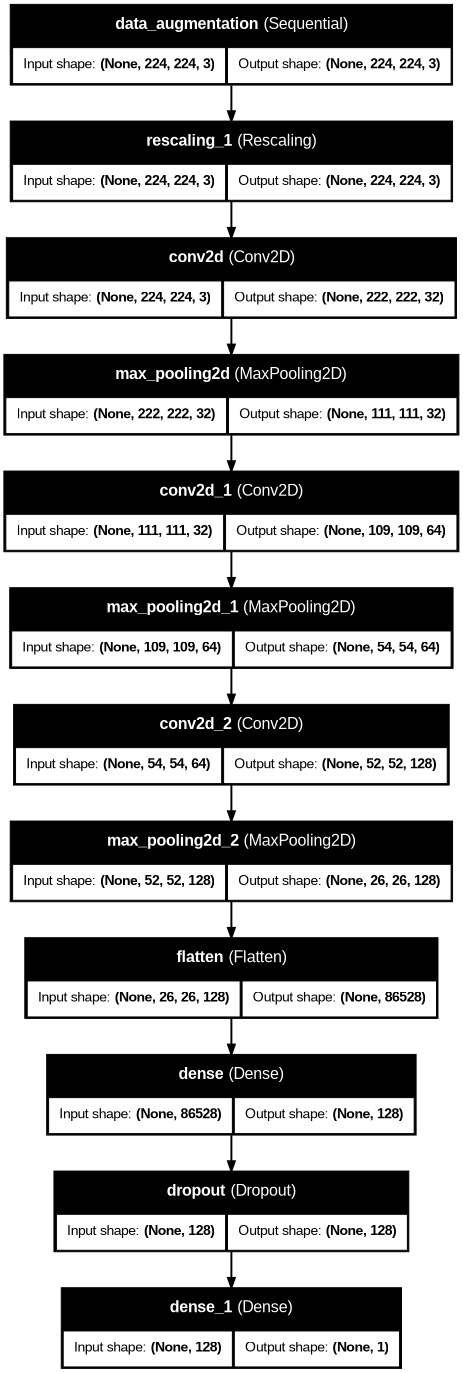

In [ ]:
# Diagrama da arquitetura (requer pydot/graphviz, que normalmente já existem no Colab)
try:
    display(tf.keras.utils.plot_model(
        model,
        show_shapes=True,
        show_layer_names=True,
        expand_nested=False,
        dpi=70
    ))
except Exception as e:
    print("Não foi possível gerar o diagrama (isso não afeta o restante do notebook).")
    print("Motivo:", e)

### Fluxo dos dados dentro da CNN

```text
Lote de imagens: (32, 224, 224, 3)      ← 32 imagens RGB de 224x224
        ↓ Conv2D(32) + MaxPool
(32, 111, 111, 32)                      ← 32 mapas de características de 111x111
        ↓ Conv2D(64) + MaxPool
(32, 54, 54, 64)
        ↓ Conv2D(128) + MaxPool
(32, 26, 26, 128)
        ↓ Flatten
(32, 86528)                             ← 26 × 26 × 128 valores por imagem
        ↓ Dense(128) + Dropout
(32, 128)
        ↓ Dense(1) + Sigmoid
(32, 1)                                 ← uma probabilidade por imagem
```

(Os tamanhos acima correspondem a imagens 224×224; se você alterar `IMG_SIZE`, confira o `model.summary()`.)

## 13. Compilação

A compilação define **como** o modelo vai aprender e **o que** será medido.

#### Adam (otimizador)
Algoritmo que ajusta os pesos da rede para reduzir a loss. É uma variação do gradiente descendente que adapta a taxa de aprendizado de cada peso e costuma funcionar bem sem muito ajuste. A **taxa de aprendizado (`learning_rate`)** controla o tamanho de cada passo: muito alta pode desestabilizar o treino; muito baixa deixa o treino lento.

#### Binary Crossentropy (função de perda)
Mede o quão distante a probabilidade prevista está do rótulo real (0 ou 1). Penaliza fortemente previsões **confiantes e erradas** (por exemplo, prever 0,99 para uma imagem cujo rótulo é 0). É a loss padrão em classificação binária com saída sigmoid.

#### Métricas
* **Accuracy:** percentual geral de previsões corretas.
* **Precision:** entre as imagens classificadas como **fraturadas**, quantas realmente pertencem à classe fraturada.
* **Recall:** entre todas as imagens **realmente fraturadas**, quantas foram identificadas pelo modelo.

> As métricas não alteram o treinamento: **apenas a loss** guia o ajuste dos pesos. As métricas servem para nós acompanharmos o desempenho.

In [ ]:
# ⚙️ TAXA DE APRENDIZADO do Adam
LEARNING_RATE = 1e-3

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')
    ]
)
print("Modelo compilado.")

Modelo compilado.


## 14. Treinamento

Durante o treinamento, a cada **época** (uma passada completa pelo conjunto de treino) a rede:

1. recebe lotes de imagens e faz previsões;
2. calcula a **loss** comparando com os rótulos reais;
3. ajusta os pesos (via *backpropagation* + Adam);
4. ao final da época, é avaliada no conjunto de **validação** (sem ajustar os pesos).

### Overfitting e Early Stopping

**Overfitting** ocorre quando o modelo **memoriza** o conjunto de treino em vez de aprender padrões gerais. Como identificar:

```text
Loss/Accuracy de TREINO  →  continuam melhorando
Loss/Accuracy de VALIDAÇÃO → param de melhorar ou pioram
```
Ou seja, a distância (*gap*) entre treino e validação vai aumentando.

O **Early Stopping** monitora a `val_loss` e **interrompe o treino** quando ela não melhora por `patience = 5` épocas seguidas. Com `restore_best_weights=True`, o modelo volta aos pesos da **melhor época** de validação, e não os da última.

### Parâmetros

* `EPOCHS`: **máximo** de épocas (o Early Stopping pode parar antes).
* `USE_CLASS_WEIGHT`: se `True`, a loss dá **mais peso à classe minoritária**, o que pode ser útil se o dataset for desbalanceado (seção 6). Com `False`, todas as imagens pesam igual.

In [ ]:
# ⚙️ NÚMERO MÁXIMO DE ÉPOCAS
EPOCHS = 20

# ⚙️ Usar pesos por classe para compensar desbalanceamento?
USE_CLASS_WEIGHT = False

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

if USE_CLASS_WEIGHT:
    n0 = train_counts[CLASS_NAMES[0]]
    n1 = train_counts[CLASS_NAMES[1]]
    total = n0 + n1
    class_weight = {0: total / (2 * n0), 1: total / (2 * n1)}
    print("class_weight:", {k: round(v, 3) for k, v in class_weight.items()})
else:
    class_weight = None
    print("class_weight: não utilizado")

t0 = time.time()

history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    class_weight=class_weight
)

print(f"\nTreinamento finalizado em {(time.time() - t0) / 60:.1f} min "
      f"({len(history.history['loss'])} épocas executadas)")

class_weight: não utilizado
Epoch 1/20
236/236 ━━━━━━━━━━━━━━━━━━━━ 21s 61ms/step - accuracy: 0.6118 - loss: 0.6461 - precision: 0.6349 - recall: 0.5457 - val_accuracy: 0.5950 - val_loss: 0.6173 - val_precision: 0.6452 - val_recall: 0.7222
Epoch 2/20
236/236 ━━━━━━━━━━━━━━━━━━━━ 14s 58ms/step - accuracy: 0.6907 - loss: 0.5690 - precision: 0.7250 - recall: 0.6253 - val_accuracy: 0.6633 - val_loss: 0.5238 - val_precision: 0.7904 - val_recall: 0.5972
Epoch 3/20
236/236 ━━━━━━━━━━━━━━━━━━━━ 14s 57ms/step - accuracy: 0.7852 - loss: 0.4478 - precision: 0.8157 - recall: 0.7429 - val_accuracy: 0.5717 - val_loss: 0.9195 - val_precision: 0.7418 - val_recall: 0.4389
Epoch 4/20
236/236 ━━━━━━━━━━━━━━━━━━━━ 13s 57ms/step - accuracy: 0.8403 - loss: 0.3514 - precision: 0.8645 - recall: 0.8112 - val_accuracy: 0.6583 - val_loss: 0.6182 - val_precision: 0.7327 - val_recall: 0.6778
Epoch 5/20
236/236 ━━━━━━━━━━━━━━━━━━━━ 14s 57ms/step - accuracy: 0.8865 - loss: 0.2646 - precision: 0.9000 - recall: 0.8724

### O que a CNN aprendeu? Mapas de características após o treino

Cada filtro `Conv2D` gera um **mapa de características**. Abaixo aplicamos as três camadas convolucionais a **uma imagem do conjunto de teste** e mostramos os 8 primeiros mapas de cada camada (já após a ReLU).

* Nas **primeiras camadas** os mapas costumam realçar bordas, contornos e contraste.
* Nas **camadas mais profundas** os mapas ficam menores e mais abstratos, difíceis de interpretar visualmente.

Isto é apenas uma janela para entender o funcionamento da rede — **não é uma explicação da decisão do modelo**, nem indica que a rede "olhou" para a fratura.

A função `obter_mapas_de_caracteristicas(modelo, imagem)` passa a imagem **camada por camada** pelo modelo e guarda a saída de cada `Conv2D`.

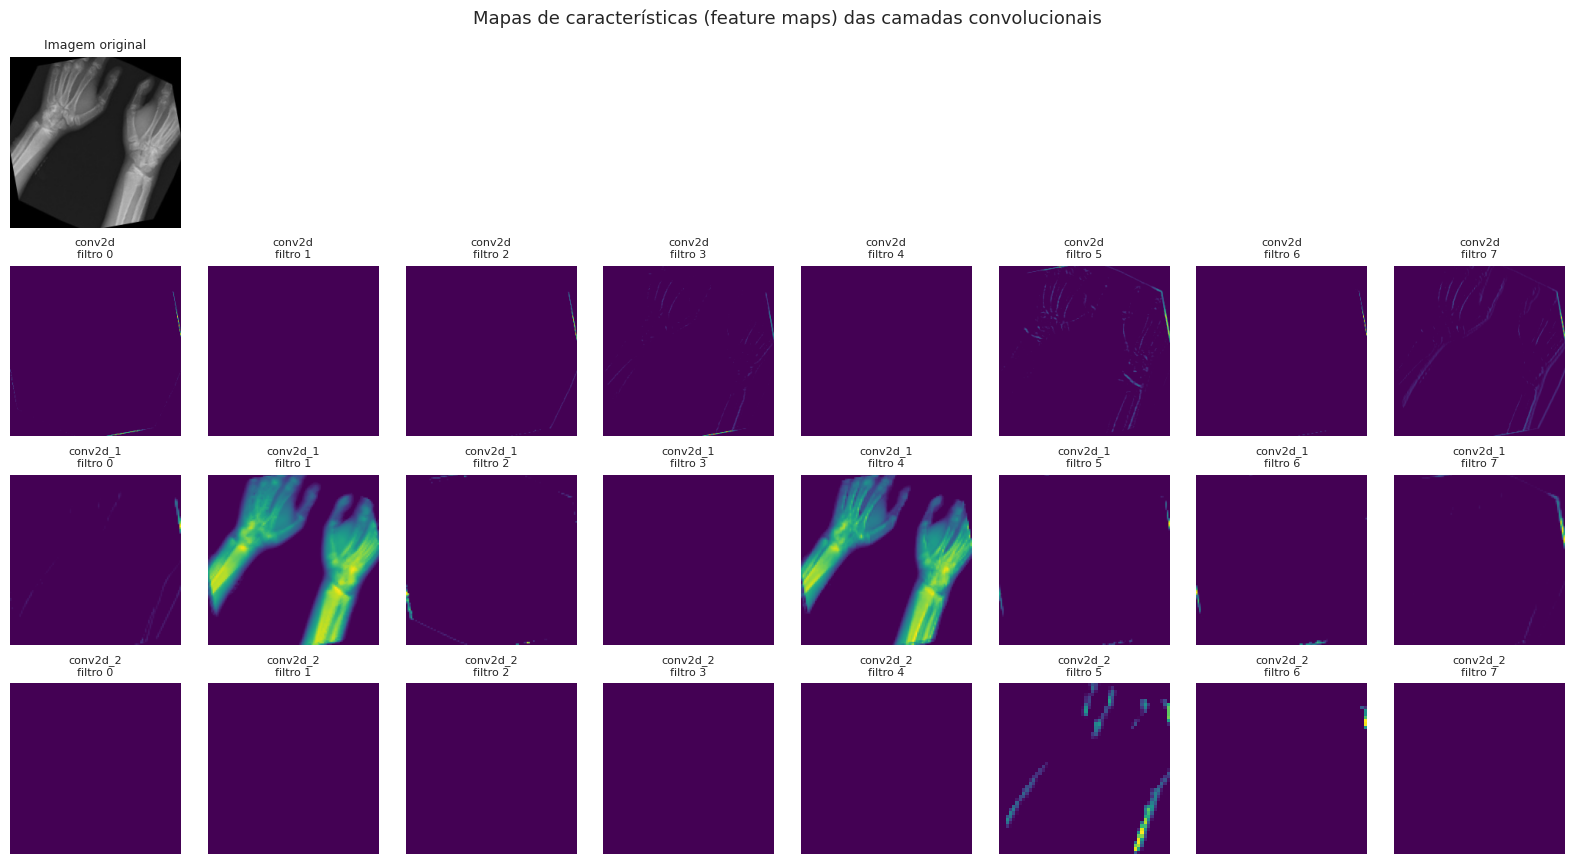

In [ ]:
def obter_mapas_de_caracteristicas(modelo, imagem):
    # imagem: array (altura, largura, 3) com pixels 0-255
    x = tf.expand_dims(imagem, 0)
    n_conv = sum(isinstance(l, layers.Conv2D) for l in modelo.layers)
    mapas = []
    for layer in modelo.layers:
        if isinstance(layer, layers.InputLayer):
            continue
        x = layer(x, training=False)
        if isinstance(layer, layers.Conv2D):
            mapas.append((layer.name, x[0].numpy()))
            if len(mapas) == n_conv:
                break
    return mapas

caminho_fm = random.Random(SEED).choice(test_file_paths)
imagem_fm = tf.keras.utils.img_to_array(tf.keras.utils.load_img(caminho_fm, target_size=IMG_SIZE))
mapas = obter_mapas_de_caracteristicas(model, imagem_fm)

N_MAPAS = 8
fig, axes = plt.subplots(len(mapas) + 1, N_MAPAS, figsize=(16, 2.2 * (len(mapas) + 1)))
for ax in axes.ravel():
    ax.axis("off")
axes[0, 0].imshow(imagem_fm.astype("uint8"))
axes[0, 0].set_title("Imagem original", fontsize=9)

for linha, (nome, fm) in enumerate(mapas, start=1):
    for j in range(N_MAPAS):
        axes[linha, j].imshow(fm[:, :, j], cmap="viridis")
        axes[linha, j].set_title(f"{nome}\nfiltro {j}", fontsize=8)
plt.suptitle("Mapas de características (feature maps) das camadas convolucionais", fontsize=13)
plt.tight_layout()
plt.show()

## 15. Curva de Accuracy

O gráfico mostra a Accuracy de **treino** e de **validação** a cada época. A linha tracejada vertical indica a **melhor época** (menor `val_loss`), cujos pesos foram restaurados pelo Early Stopping.

### Como interpretar

* **Ambas subindo e próximas** → a rede está aprendendo padrões que generalizam para dados não vistos.
* **Treino sobe, validação estagna ou cai** → sinal de **overfitting**.
* **Ambas baixas** → a rede pode estar com **underfitting** (modelo simples demais, poucas épocas, learning rate inadequado ou dados difíceis).
* **Validação oscilando muito** → conjunto de validação pequeno ou treino instável.

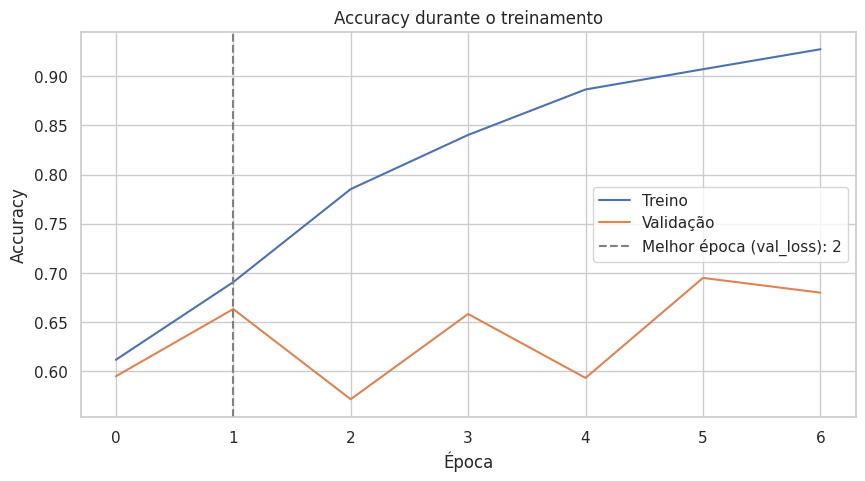

Última época   -> Accuracy treino: 0.9274 | validação: 0.6800
Melhor época (2) -> Accuracy treino: 0.6907 | validação: 0.6633


In [ ]:
best_epoch = int(np.argmin(history.history['val_loss']))

plt.figure(figsize=(10, 5))

plt.plot(
    history.history['accuracy'],
    label='Treino'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validação'
)

plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Melhor época (val_loss): {best_epoch + 1}')
plt.title('Accuracy durante o treinamento')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

print(f"Última época   -> Accuracy treino: {history.history['accuracy'][-1]:.4f} | validação: {history.history['val_accuracy'][-1]:.4f}")
print(f"Melhor época ({best_epoch + 1}) -> Accuracy treino: {history.history['accuracy'][best_epoch]:.4f} | validação: {history.history['val_accuracy'][best_epoch]:.4f}")

## 16. Curva de Loss

A **loss** é o valor que o treinamento tenta **minimizar**. Menor é melhor.

* **Loss de treinamento:** erro nas imagens usadas para ajustar os pesos. Espera-se que **diminua** ao longo das épocas.
* **Loss de validação:** erro em imagens que **não** ajustam os pesos. É a melhor referência para saber se o modelo está generalizando.

### Sinais de overfitting

```text
Loss de treino ↓ (continua caindo)
Loss de validação ↑ (começa a subir) ou fica estagnada
```
O ponto em que a `val_loss` para de melhorar é justamente o que o Early Stopping usa para escolher os pesos.

> Detalhe: com Data Augmentation e Dropout ativos no treino, a loss de **treino** (calculada com essas perturbações) pode ficar **maior** que a de validação, principalmente nas primeiras épocas. Isso é normal.

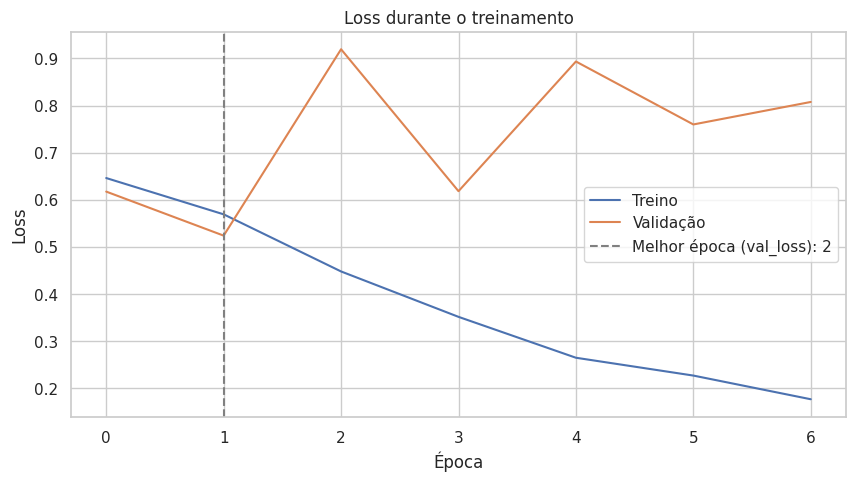

Na melhor época (2): loss treino = 0.5690 | loss validação = 0.5238 | diferença = -0.0452


In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history['loss'],
    label='Treino'
)

plt.plot(
    history.history['val_loss'],
    label='Validação'
)

plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Melhor época (val_loss): {best_epoch + 1}')
plt.title('Loss durante o treinamento')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.show()

gap = history.history['val_loss'][best_epoch] - history.history['loss'][best_epoch]
print(f"Na melhor época ({best_epoch + 1}): loss treino = {history.history['loss'][best_epoch]:.4f} | "
      f"loss validação = {history.history['val_loss'][best_epoch]:.4f} | diferença = {gap:+.4f}")

## 17. Avaliação no conjunto de teste

Agora avaliamos o modelo no **conjunto de teste**.

**Por que o teste deve permanecer separado?**
O conjunto de validação já influenciou o treinamento (escolha da melhor época pelo Early Stopping, ajuste de hiperparâmetros). Se usássemos o teste nessas decisões, ele deixaria de ser uma amostra "nunca vista" e a avaliação final ficaria **otimista demais**. O teste só é usado **aqui**, ao final, para estimar o desempenho em imagens novas — **do mesmo dataset**.

Se você ajustar hiperparâmetros olhando para o resultado do teste e repetir o processo várias vezes, estará "vazando" informação do teste para o modelo. Nesse caso, o ideal é reservar outro conjunto final.

In [ ]:
results = model.evaluate(test_ds, return_dict=True)

print("\n===== RESULTADOS NO CONJUNTO DE TESTE =====")
print(f"Test Loss      : {results['loss']:.4f}")
print(f"Test Accuracy  : {results['accuracy']:.4f}  ({results['accuracy']:.2%})")
print(f"Test Precision : {results['precision']:.4f}  ({results['precision']:.2%})")
print(f"Test Recall    : {results['recall']:.4f}  ({results['recall']:.2%})")

42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.7976 - loss: 0.4438 - precision: 0.8618 - recall: 0.7143

===== RESULTADOS NO CONJUNTO DE TESTE =====
Test Loss      : 0.4438
Test Accuracy  : 0.7976  (79.76%)
Test Precision : 0.8618  (86.18%)
Test Recall    : 0.7143  (71.43%)


## 18. Geração das previsões

Para analisar os erros em detalhe, percorremos o dataset de teste **lote a lote** e coletamos:

* `y_true`: os **rótulos reais** (0 ou 1);
* `y_pred_probability`: a **probabilidade estimada** de fratura, produzida pela sigmoid.

Depois convertemos probabilidades em classes usando um **threshold**:

```text
probabilidade >= THRESHOLD → Fraturado    (classe 1)
probabilidade <  THRESHOLD → Sem fratura  (classe 0)
```

O valor `0.5` é apenas o padrão. **Aumentar** o threshold torna o modelo mais "exigente" para dizer *Fraturado* (tende a aumentar Precision e reduzir Recall); **diminuir** faz o contrário. Na seção 25 mostramos essa troca de forma tabelada.

Como `shuffle=False` no teste, a ordem das previsões coincide com `test_file_paths`. Reunimos tudo em uma tabela (`df_pred`) que será reutilizada na análise dos acertos e erros.

In [ ]:
# ⚙️ THRESHOLD de decisão
THRESHOLD = 0.5

y_true = []
y_pred_probability = []

for images, labels in test_ds:
    probs = model(images, training=False).numpy().ravel()   # training=False: sem Dropout/augmentation
    y_true.append(labels.numpy().ravel())
    y_pred_probability.append(probs)

y_true = np.concatenate(y_true).astype(int)
y_pred_probability = np.concatenate(y_pred_probability)

y_pred = (y_pred_probability >= THRESHOLD).astype(int)

assert len(y_true) == len(test_file_paths), "A quantidade de previsões não bate com a quantidade de arquivos."

df_pred = pd.DataFrame({
    "arquivo": test_file_paths,
    "real": y_true,
    "prob_fratura": y_pred_probability,
    "pred": y_pred
})
df_pred["acertou"] = df_pred["real"] == df_pred["pred"]

print(f"Imagens de teste: {len(df_pred)} | acertos: {int(df_pred['acertou'].sum())} | erros: {int((~df_pred['acertou']).sum())}")
print(f"Threshold utilizado: {THRESHOLD}\n")
display(df_pred.head(10))

Imagens de teste: 1329 | acertos: 1060 | erros: 269
Threshold utilizado: 0.5



,arquivo,real,prob_fratura,pred,acertou
0,/content/dataset_local/test/not fractured/10-r...,0,0.438748,0,True
1,/content/dataset_local/test/not fractured/10-r...,0,0.463560,0,True
2,/content/dataset_local/test/not fractured/10-r...,0,0.158426,0,True
3,/content/dataset_local/test/not fractured/10-r...,0,0.112388,0,True
4,/content/dataset_local/test/not fractured/10-r...,0,0.115339,0,True
5,/content/dataset_local/test/not fractured/10-r...,0,0.440993,0,True
6,/content/dataset_local/test/not fractured/10-r...,0,0.257432,0,True
7,/content/dataset_local/test/not fractured/10-r...,0,0.462832,0,True
8,/content/dataset_local/test/not fractured/10-r...,0,0.239557,0,True
9,/content/dataset_local/test/not fractured/10-r...,0,0.493577,0,True


## 19. Matriz de Confusão

A matriz de confusão cruza a **classe real** (linhas) com a **classe prevista** (colunas):

|  | Previsto: Sem fratura | Previsto: Fraturado |
| --- | :---: | :---: |
| **Real: Sem fratura** | True Negative (TN) | False Positive (FP) |
| **Real: Fraturado** | False Negative (FN) | True Positive (TP) |

* **True Negative (TN):** imagem **sem fratura** corretamente identificada como sem fratura.
* **False Positive (FP):** imagem **sem fratura** classificada como **fraturada** (falso alarme).
* **False Negative (FN):** imagem **com fratura** classificada como **sem fratura**.
* **True Positive (TP):** imagem **com fratura** corretamente identificada.

> 🔎 **Atenção especial ao False Negative:** ele representa uma **fratura que o modelo não identificou**. É o tipo de erro que mais merece investigação, porque mostra em que situações o modelo deixa de reconhecer o padrão que deveria aprender. Em contexto real, o "custo" de FN e FP depende do uso pretendido, e essa é uma decisão que não cabe a este notebook.

À direita, a mesma matriz **normalizada por linha** (percentual de cada classe real), o que facilita a leitura quando as classes têm quantidades diferentes.

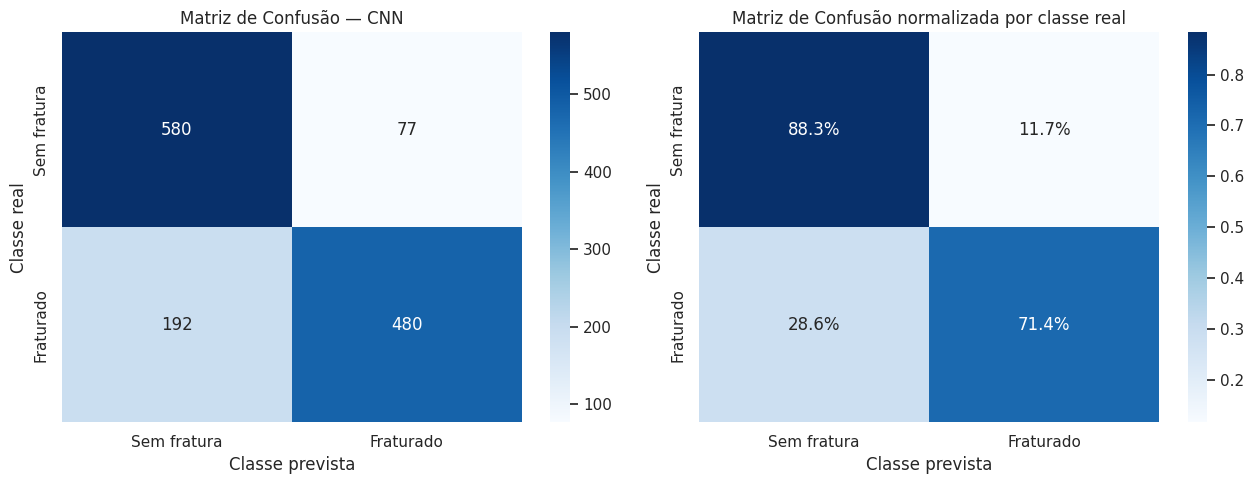

True Negative  (TN): 580  -> sem fratura corretamente identificada
False Positive (FP): 77  -> sem fratura classificada como fraturada
False Negative (FN): 192  -> fratura classificada como sem fratura
True Positive  (TP): 480  -> fratura corretamente identificada


In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=DISPLAY_NAMES,
    yticklabels=DISPLAY_NAMES,
    ax=axes[0]
)
axes[0].set_title('Matriz de Confusão — CNN')
axes[0].set_xlabel('Classe prevista')
axes[0].set_ylabel('Classe real')

cm_norm = cm / cm.sum(axis=1, keepdims=True)
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.1%',
    cmap='Blues',
    xticklabels=DISPLAY_NAMES,
    yticklabels=DISPLAY_NAMES,
    ax=axes[1]
)
axes[1].set_title('Matriz de Confusão normalizada por classe real')
axes[1].set_xlabel('Classe prevista')
axes[1].set_ylabel('Classe real')

plt.tight_layout()
plt.show()

print(f"True Negative  (TN): {tn}  -> sem fratura corretamente identificada")
print(f"False Positive (FP): {fp}  -> sem fratura classificada como fraturada")
print(f"False Negative (FN): {fn}  -> fratura classificada como sem fratura")
print(f"True Positive  (TP): {tp}  -> fratura corretamente identificada")

## 20. Precision

```text
Precision responde:

"Quando o modelo disse que era fratura,
quantas dessas previsões realmente eram fraturas?"
```

$$\text{Precision} = \frac{TP}{TP + FP}$$

Uma Precision baixa indica muitos **falsos alarmes** (imagens sem fratura classificadas como fraturadas).

In [ ]:
precision = precision_score(
    y_true,
    y_pred,
    zero_division=0
)

print(f"Precision (sklearn): {precision:.4f} = {precision:.2%}")
print(f"Conferência manual : TP / (TP + FP) = {tp} / ({tp} + {fp}) = {tp / max(tp + fp, 1):.4f}")

Precision (sklearn): 0.8618 = 86.18%
Conferência manual : TP / (TP + FP) = 480 / (480 + 77) = 0.8618


## 21. Recall

```text
Recall responde:

"De todas as imagens que realmente possuíam fratura,
quantas foram identificadas pelo modelo?"
```

$$\text{Recall} = \frac{TP}{TP + FN}$$

O **Recall** é uma métrica importante para analisar a **capacidade do modelo de encontrar os exemplos positivos**. Um Recall baixo indica muitos **False Negatives**.

> Nenhuma métrica isolada determina a qualidade clínica de um modelo. Recall alto com Precision muito baixa (o modelo "acusa" fratura em quase tudo), ou o contrário, são situações que só aparecem quando **as métricas são lidas em conjunto**.

Como complemento, calculamos também a **Especificidade** (o "Recall" da classe *Sem fratura*): entre as imagens realmente sem fratura, quantas o modelo identificou corretamente.

In [ ]:
recall = recall_score(
    y_true,
    y_pred,
    zero_division=0
)

specificity = tn / max(tn + fp, 1)

print(f"Recall (sklearn)   : {recall:.4f} = {recall:.2%}")
print(f"Conferência manual : TP / (TP + FN) = {tp} / ({tp} + {fn}) = {tp / max(tp + fn, 1):.4f}")
print(f"\nEspecificidade     : TN / (TN + FP) = {tn} / ({tn} + {fp}) = {specificity:.2%}")

Recall (sklearn)   : 0.7143 = 71.43%
Conferência manual : TP / (TP + FN) = 480 / (480 + 192) = 0.7143

Especificidade     : TN / (TN + FP) = 580 / (580 + 77) = 88.28%


## 22. F1-Score

O **F1-Score** combina Precision e Recall em um único número, usando a **média harmônica**:

$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$

A média harmônica é dominada pelo menor valor: para o F1 ser alto, **Precision e Recall precisam ser altos ao mesmo tempo**. Um modelo com Precision = 100% e Recall = 10% terá F1 baixo.

In [ ]:
f1 = f1_score(
    y_true,
    y_pred,
    zero_division=0
)

accuracy = accuracy_score(y_true, y_pred)

print(f"F1-Score (sklearn): {f1:.4f} = {f1:.2%}")
print(f"Conferência manual: {2 * precision * recall / max(precision + recall, 1e-12):.4f}")

F1-Score (sklearn): 0.7811 = 78.11%
Conferência manual: 0.7811


### Tabela final das métricas

A tabela é gerada automaticamente a partir das previsões do conjunto de teste (com o `THRESHOLD` definido).

In [ ]:
display(Markdown(f"""
| Métrica   | Resultado |
| --------- | --------: |
| Accuracy  | {accuracy:.2%} |
| Precision | {precision:.2%} |
| Recall    | {recall:.2%} |
| F1-Score  | {f1:.2%} |
"""))


| Métrica   | Resultado |
| --------- | --------: |
| Accuracy  | 79.76% |
| Precision | 86.18% |
| Recall    | 71.43% |
| F1-Score  | 78.11% |


## 23. Classification Report

O `classification_report` do scikit-learn resume as métricas **para cada classe**:

| Coluna | Significado |
| --- | --- |
| `precision` | Das imagens previstas como essa classe, quantas realmente eram dela |
| `recall` | Das imagens que realmente eram dessa classe, quantas o modelo encontrou |
| `f1-score` | Média harmônica entre precision e recall |
| `support` | Quantidade de imagens reais dessa classe no teste |

Nas linhas finais:

* **accuracy:** proporção geral de acertos;
* **macro avg:** média simples entre as classes (trata as duas como igualmente importantes);
* **weighted avg:** média ponderada pelo `support` (classes maiores pesam mais).

Compare o *recall* de cada classe: um desempenho muito diferente entre elas é um sinal de que a Accuracy geral esconde algum problema.

In [ ]:
report = classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=DISPLAY_NAMES,
    digits=4,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

 Sem fratura     0.7513    0.8828    0.8118       657
   Fraturado     0.8618    0.7143    0.7811       672

    accuracy                         0.7976      1329
   macro avg     0.8065    0.7985    0.7964      1329
weighted avg     0.8072    0.7976    0.7963      1329



## 24. Curva ROC e AUC

As métricas anteriores dependem de **um único threshold** (0,5). A **curva ROC** mostra o comportamento do modelo **para todos os thresholds possíveis**:

* Eixo X — **False Positive Rate (FPR)** = FP / (FP + TN): proporção de imagens sem fratura classificadas como fraturadas.
* Eixo Y — **True Positive Rate (TPR)** = Recall = TP / (TP + FN).

Cada ponto da curva corresponde a um threshold. A **linha diagonal** representa um classificador que "chuta" (sem capacidade de separar as classes). Quanto mais a curva se aproxima do **canto superior esquerdo**, melhor a separação.

O **AUC** (*Area Under the Curve*) resume a curva em um número:

| AUC | Leitura |
| --- | --- |
| 0,5 | Equivalente a chute aleatório |
| entre 0,5 e 1 | Quanto mais próximo de 1, melhor o modelo **ordena** imagens fraturadas acima das não fraturadas |
| 1,0 | Separação perfeita |

O AUC pode ser interpretado como a probabilidade de que uma imagem **fraturada** sorteada ao acaso receba uma pontuação **maior** que a de uma imagem **sem fratura** sorteada ao acaso.

O ponto vermelho marca a posição correspondente ao `THRESHOLD` atualmente utilizado.

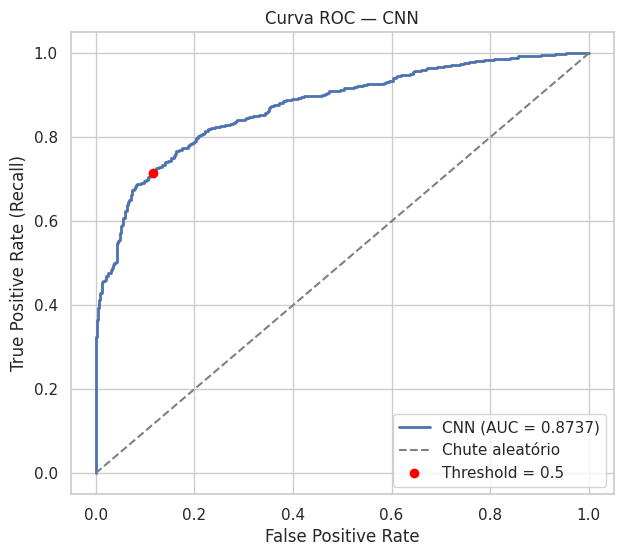

AUC = 0.8737


In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_pred_probability
)

roc_auc = auc(
    fpr,
    tpr
)

# Ponto de operação correspondente ao THRESHOLD atual
fpr_op = fp / max(fp + tn, 1)
tpr_op = tp / max(tp + fn, 1)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'CNN (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chute aleatório')
plt.scatter([fpr_op], [tpr_op], color='red', zorder=5, label=f'Threshold = {THRESHOLD}')
plt.title('Curva ROC — CNN')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.show()

print(f"AUC = {roc_auc:.4f}")

## 25. Precision-Recall Curve

A curva **Precision × Recall** mostra a troca entre os dois ao variar o threshold:

* Threshold **alto** → o modelo só diz "Fraturado" quando está muito confiante → Precision tende a subir, Recall tende a cair.
* Threshold **baixo** → o modelo diz "Fraturado" com facilidade → Recall tende a subir, Precision tende a cair.

**Por que essa análise é útil, principalmente com classes desbalanceadas?**
A curva ROC usa a taxa de falsos positivos, que é calculada em relação a **todas** as imagens negativas; se elas forem muitas, o FPR permanece pequeno mesmo com vários falsos positivos, e a ROC pode parecer melhor do que a experiência prática sugere. A curva Precision-Recall foca **apenas na classe positiva** (Fratura) e reflete diretamente o efeito dos falsos positivos sobre a Precision.

A linha tracejada horizontal mostra o **desempenho de referência** de um classificador sem habilidade: uma Precision igual à **proporção de positivos** no teste. O **Average Precision (AP)** resume a área sob a curva.

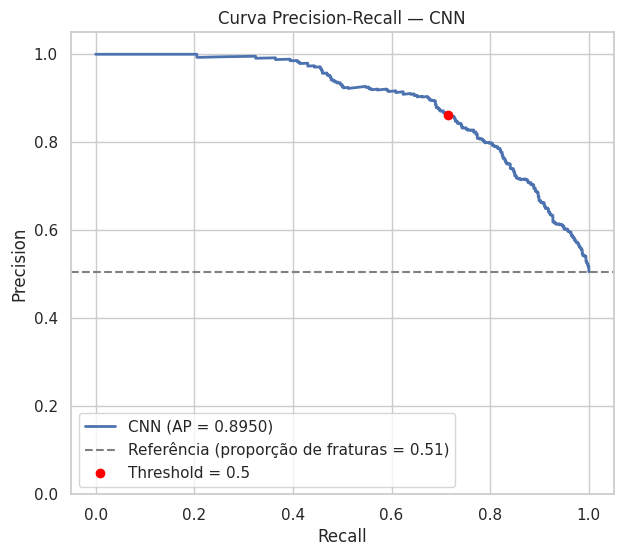

Average Precision (AP) = 0.8950


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_true,
    y_pred_probability
)

average_precision = average_precision_score(y_true, y_pred_probability)
baseline = y_true.mean()   # proporção de positivos no teste

plt.figure(figsize=(7, 6))
plt.plot(recalls, precisions, linewidth=2, label=f'CNN (AP = {average_precision:.4f})')
plt.axhline(baseline, linestyle='--', color='gray', label=f'Referência (proporção de fraturas = {baseline:.2f})')
plt.scatter([recall], [precision], color='red', zorder=5, label=f'Threshold = {THRESHOLD}')
plt.title('Curva Precision-Recall — CNN')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.ylim(0, 1.05)
plt.legend(loc='lower left')
plt.show()

print(f"Average Precision (AP) = {average_precision:.4f}")

### Efeito do threshold

A tabela abaixo mostra, para diferentes thresholds, como Precision, Recall, F1 e o número de erros (FP e FN) mudam **neste conjunto de teste**. Ela serve para **entender** a troca entre os erros.

> ⚠️ Não escolha o threshold "ideal" olhando para o teste e depois relatar o resultado no mesmo teste: isso seria otimista. Se quiser ajustar o threshold, faça a escolha usando o **conjunto de validação**.

In [ ]:
linhas = []
for t in np.arange(0.1, 1.0, 0.1):
    p = (y_pred_probability >= t).astype(int)
    linhas.append({
        "Threshold": round(float(t), 1),
        "Precision": precision_score(y_true, p, zero_division=0),
        "Recall": recall_score(y_true, p, zero_division=0),
        "F1": f1_score(y_true, p, zero_division=0),
        "FP": int(((y_true == 0) & (p == 1)).sum()),
        "FN": int(((y_true == 1) & (p == 0)).sum()),
    })

display(pd.DataFrame(linhas).set_index("Threshold").round(3))

,Precision,Recall,F1,FP,FN
Threshold,,,,,
0.1,0.520,0.999,0.684,620,1
0.2,0.560,0.984,0.713,520,11
0.3,0.640,0.920,0.755,348,54
0.4,0.756,0.832,0.792,180,113
0.5,0.862,0.714,0.781,77,192
0.6,0.917,0.607,0.731,37,264
0.7,0.935,0.491,0.644,23,342
0.8,0.980,0.427,0.595,6,385
0.9,0.992,0.356,0.524,2,433


## 26. Exemplos de previsões corretas

Números resumem o desempenho, mas **olhar as imagens** mostra *como* o modelo se comporta.

### Função criada nesta seção

`mostrar_grade(df_sel, titulo, ncols=4)`: recebe um recorte da tabela `df_pred` (uma linha por imagem) e desenha uma **grade de imagens**. Para cada imagem, o título mostra:

```text
✔ ACERTO  ou  ✘ ERRO
Real: <classe real>
Predito: <classe prevista>
P(fratura): <probabilidade estimada pelo modelo>
```

A **cor do título** (verde = acerto, vermelho = erro) ajuda na leitura, mas a informação **não depende só da cor**: os símbolos ✔/✘ e o texto "ACERTO"/"ERRO" também indicam o resultado.

`P(fratura)` é a saída da sigmoid: a probabilidade estimada pelo modelo para a classe *Fraturado*, independentemente da classe predita. Por exemplo, uma imagem prevista como *Sem fratura* com `P(fratura) = 12%` foi prevista assim porque 12% está abaixo do threshold.

In [ ]:
def mostrar_grade(df_sel, titulo, ncols=4):
    # Desenha uma grade de imagens a partir de linhas de df_pred
    n = len(df_sel)
    if n == 0:
        print("Nenhuma imagem para mostrar.")
        return
    nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=(3.4 * ncols, 4.6 * nrows))
    for i, (_, linha) in enumerate(df_sel.iterrows()):
        plt.subplot(nrows, ncols, i + 1)
        img = tf.keras.utils.load_img(linha["arquivo"], target_size=IMG_SIZE)
        plt.imshow(img)
        acertou = int(linha["real"]) == int(linha["pred"])
        cor = "green" if acertou else "red"
        marca = "✔ ACERTO" if acertou else "✘ ERRO"
        plt.title(
            f"{marca}\n"
            f"Real: {DISPLAY_NAMES[int(linha['real'])]}\n"
            f"Predito: {DISPLAY_NAMES[int(linha['pred'])]}\n"
            f"P(fratura): {linha['prob_fratura']:.2%}",
            color=cor, fontsize=9
        )
        plt.axis("off")
    plt.suptitle(titulo, fontsize=14, y=0.995)
    plt.tight_layout(rect=(0, 0, 1, 0.97))
    plt.show()


def amostrar(df, n, seed=SEED):
    # Sorteia até n linhas (ou todas, se houver menos)
    return df.sample(n=min(n, len(df)), random_state=seed)

### Exemplos de previsões da CNN (amostra aleatória de 16 imagens do teste)

Uma amostra **sem filtro**: mistura acertos e erros na proporção em que eles realmente ocorrem.

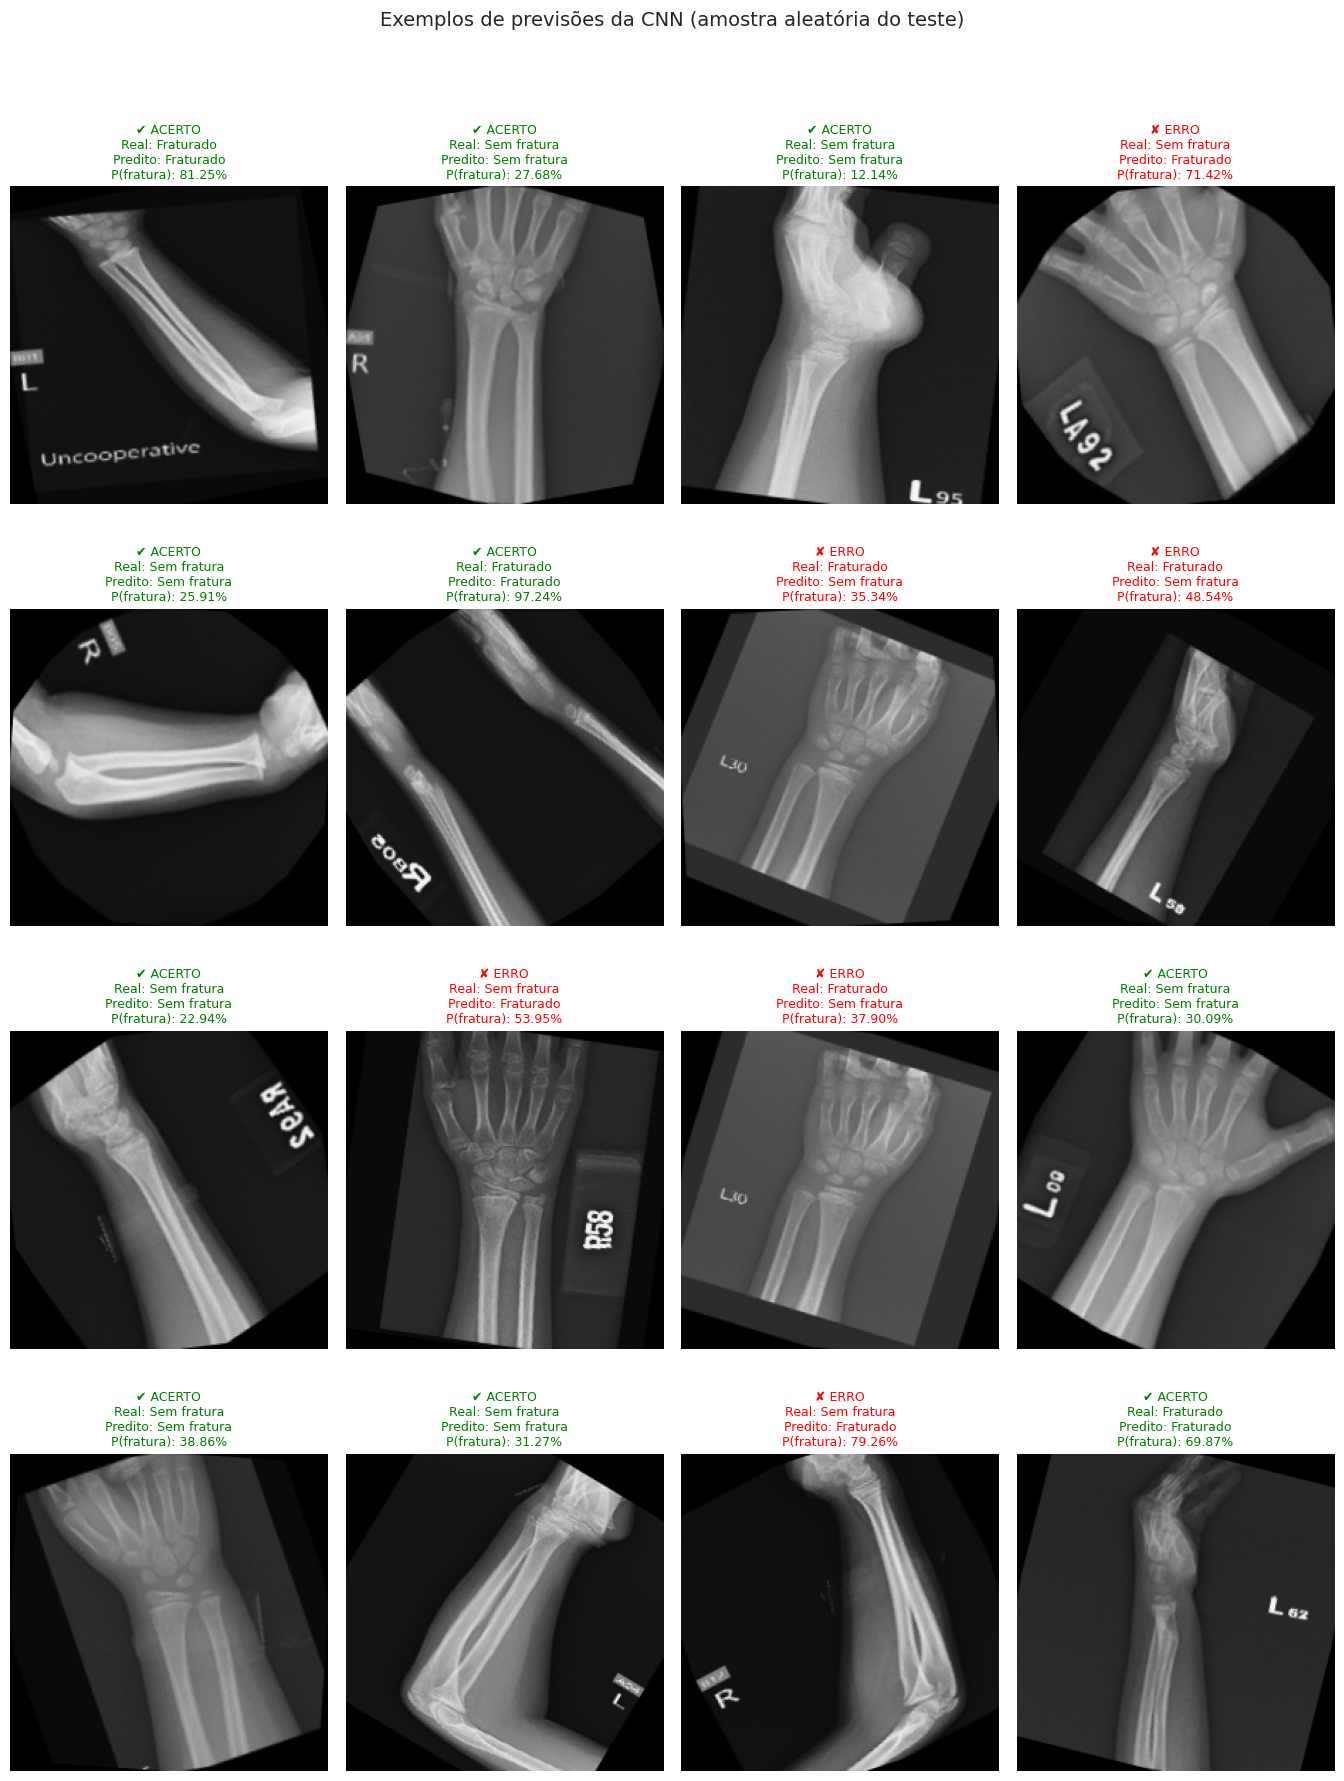

In [ ]:
mostrar_grade(amostrar(df_pred, 16), "Exemplos de previsões da CNN (amostra aleatória do teste)")

### Classificações corretas

Até 8 imagens classificadas **corretamente**: 4 fraturadas (True Positives) e 4 sem fratura (True Negatives), quando existirem.

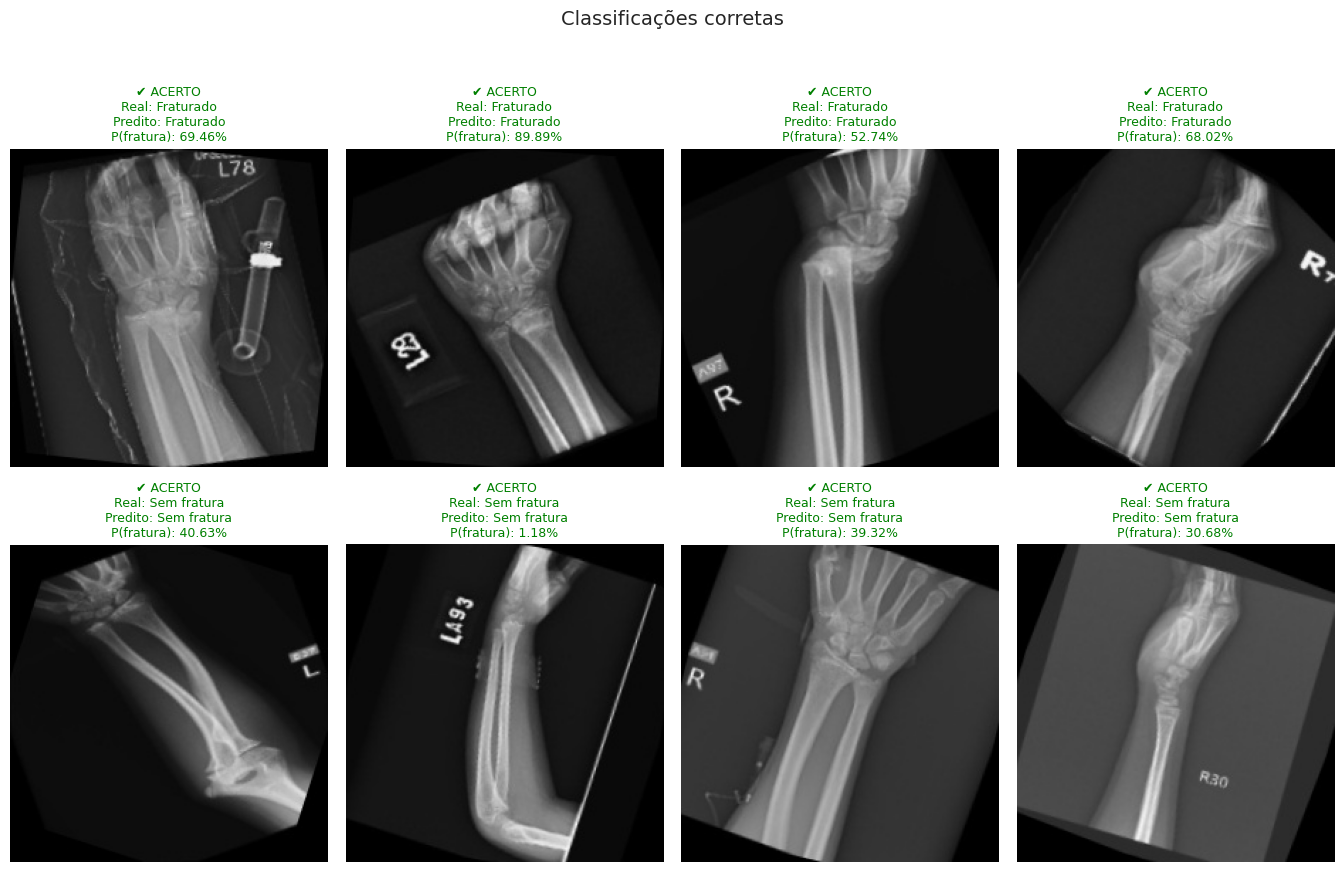

In [ ]:
corretos = df_pred[df_pred["acertou"]]

tp_df = corretos[corretos["real"] == 1]
tn_df = corretos[corretos["real"] == 0]

sel_corretos = pd.concat([amostrar(tp_df, 4), amostrar(tn_df, 4)])

mostrar_grade(sel_corretos, "Classificações corretas")

## 27. Exemplos de previsões incorretas

Aqui mostramos até 8 imagens **classificadas incorretamente**, escolhendo as **de maior confiança errada** (aquelas em que a probabilidade estava mais distante do rótulo real).

Essas imagens são muito importantes para **investigar quais padrões visuais estão causando dificuldade para a CNN**. Ao observá-las, pergunte-se:

* A imagem tem baixa qualidade, contraste ruim ou está mal posicionada/cortada?
* Há **objetos, textos, marcações, gesso, implantes** ou outras estruturas que possam confundir o modelo?
* A fratura é **muito sutil** ou está em uma região pouco representada no treino?
* O **rótulo** original pode estar errado? (Erros de rotulagem em datasets existem e aparecem como "erros muito confiantes".)

Total de erros no teste: 269 de 1329 (20.24%)


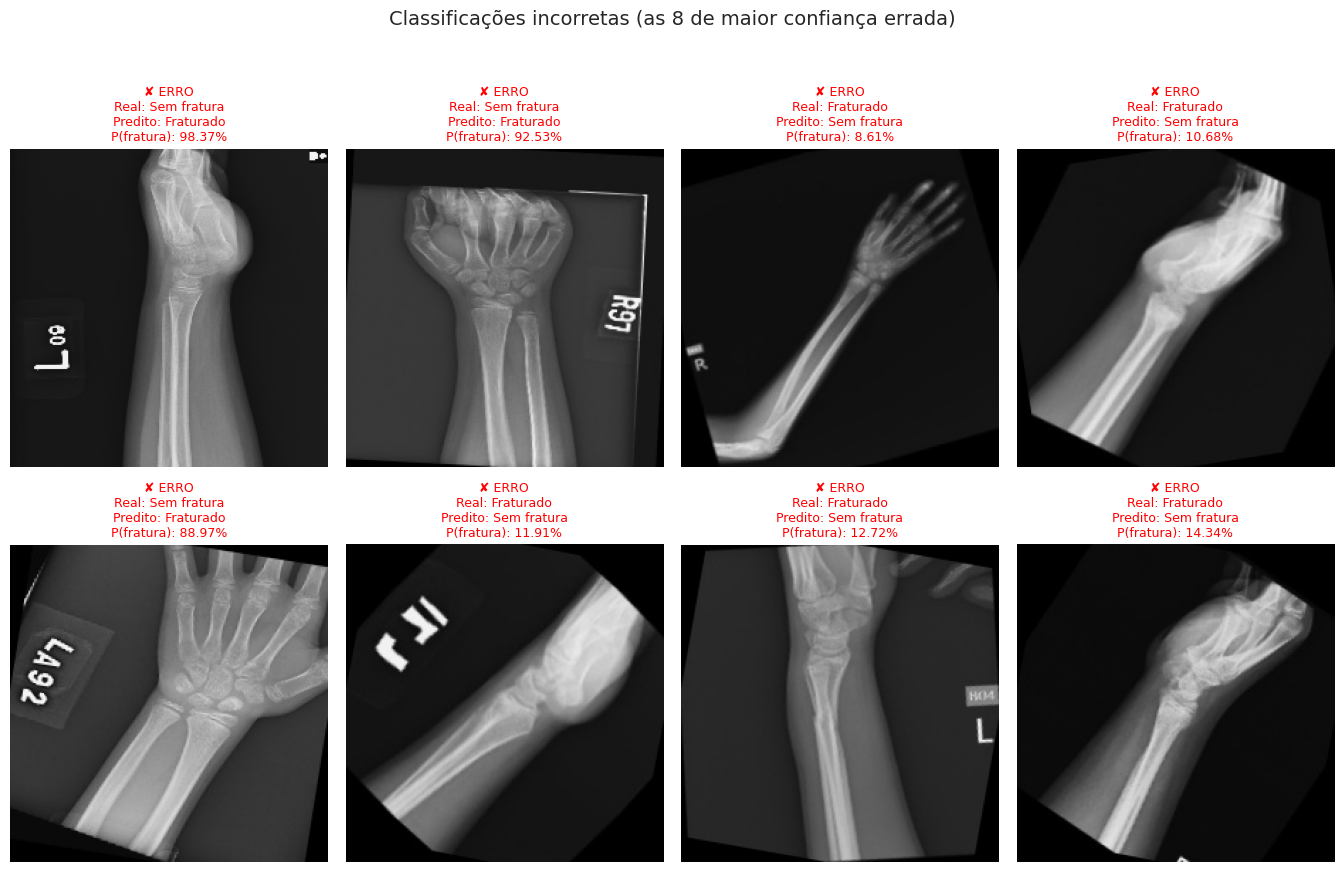

In [ ]:
erros = df_pred[~df_pred["acertou"]].copy()
erros["confianca_errada"] = (erros["prob_fratura"] - erros["real"]).abs()

print(f"Total de erros no teste: {len(erros)} de {len(df_pred)} ({len(erros) / len(df_pred):.2%})")

mostrar_grade(
    erros.sort_values("confianca_errada", ascending=False).head(8),
    "Classificações incorretas (as 8 de maior confiança errada)"
)

## 28. Análise dos falsos negativos

Filtramos as imagens em que:

```text
Real = Fraturado
Predito = Sem fratura
```

```text
Esses casos são particularmente importantes para a análise
do comportamento do modelo porque representam imagens em que
uma fratura presente no dataset não foi identificada pelo modelo.
```

Isso **não representa automaticamente um risco clínico real**: o dataset e o contexto desta avaliação podem não representar uma população clínica, e o modelo é experimental. O objetivo aqui é **entender o comportamento do modelo**.

As imagens são ordenadas da **menor** para a maior `P(fratura)`: as primeiras são aquelas em que o modelo estava mais "seguro" de que **não** havia fratura.

Falsos negativos: 192 de 672 imagens fraturadas (28.57% das fraturas do teste não foram identificadas com THRESHOLD = 0.5)
P(fratura) nos falsos negativos -> mín: 8.61% | mediana: 37.19% | máx: 49.90%


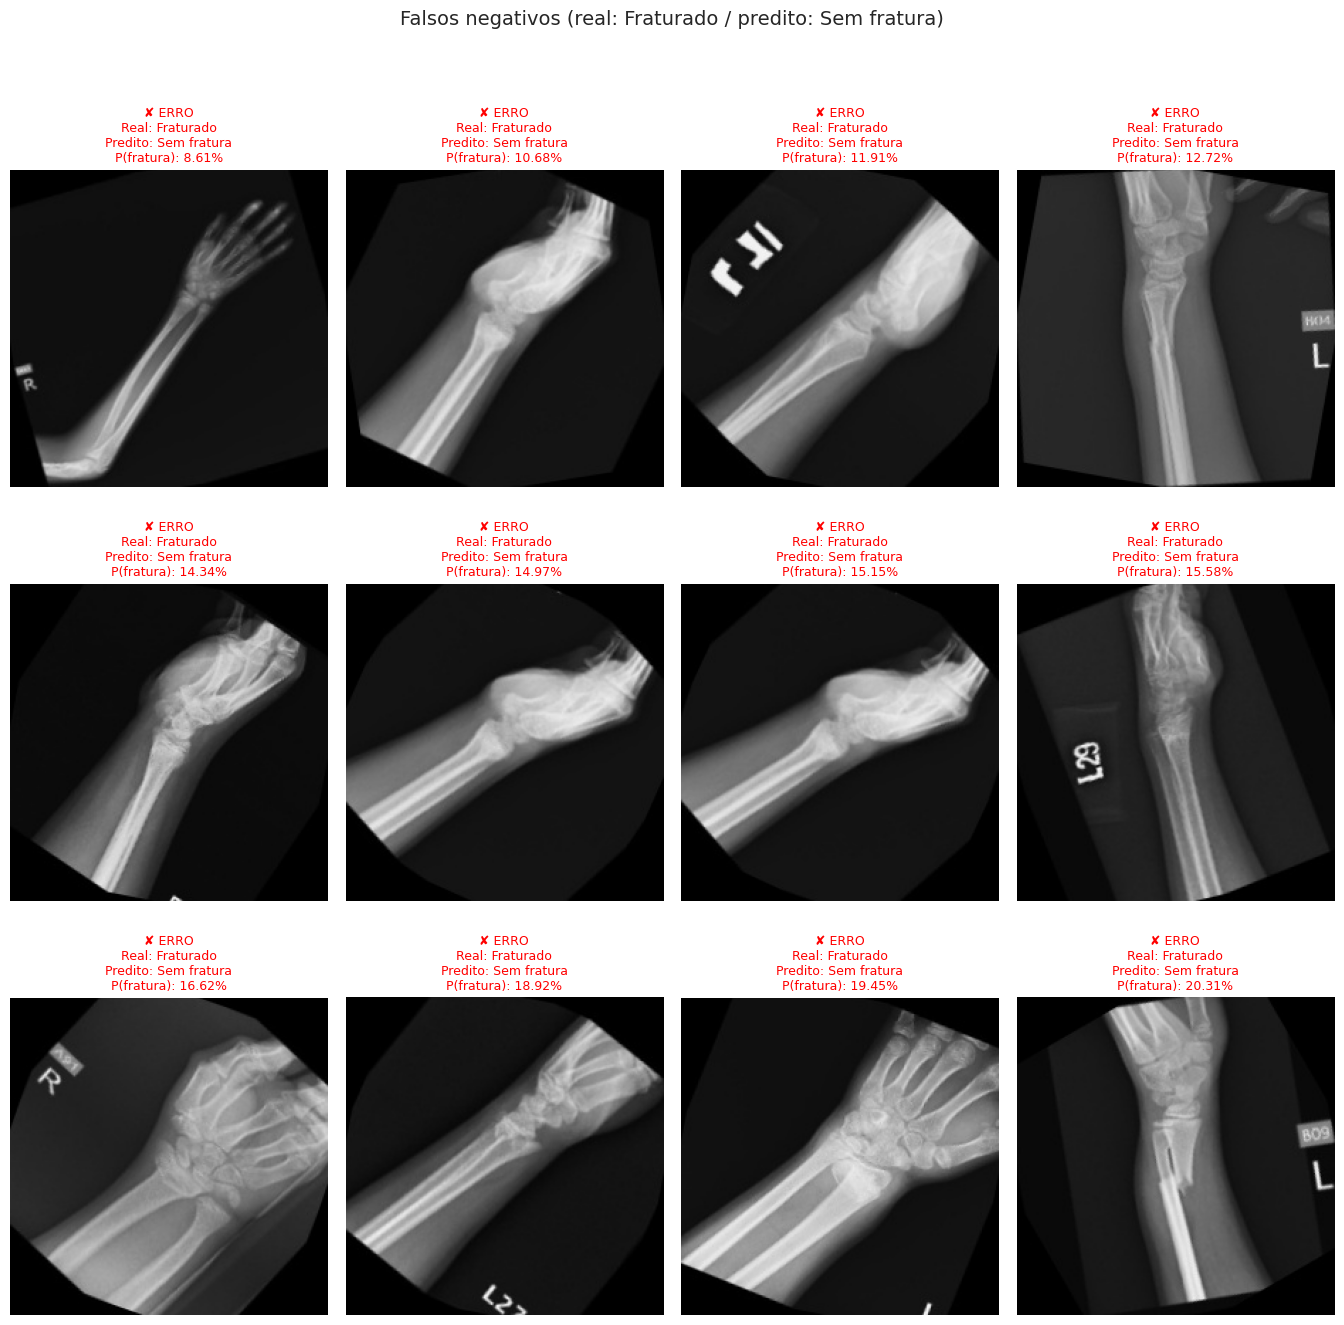

In [ ]:
falsos_negativos = df_pred[(df_pred["real"] == 1) & (df_pred["pred"] == 0)].sort_values("prob_fratura")

total_fraturas = int((df_pred["real"] == 1).sum())
print(f"Falsos negativos: {len(falsos_negativos)} de {total_fraturas} imagens fraturadas "
      f"({len(falsos_negativos) / max(total_fraturas, 1):.2%} das fraturas do teste não foram identificadas com THRESHOLD = {THRESHOLD})")

if len(falsos_negativos) > 0:
    print(f"P(fratura) nos falsos negativos -> mín: {falsos_negativos['prob_fratura'].min():.2%} | "
          f"mediana: {falsos_negativos['prob_fratura'].median():.2%} | máx: {falsos_negativos['prob_fratura'].max():.2%}")

mostrar_grade(falsos_negativos.head(12), "Falsos negativos (real: Fraturado / predito: Sem fratura)")

## 29. Análise dos falsos positivos

Filtramos as imagens em que:

```text
Real = Sem fratura
Predito = Fraturado
```

São os "falsos alarmes". Investigue se há algo nessas imagens (posição, projeção, calcificações, cicatrizes antigas, material de fixação, marcações, artefatos) que **se assemelhe** ao que o modelo aprendeu a associar à fratura.

As imagens são ordenadas da **maior** para a menor `P(fratura)`.

Falsos positivos: 77 de 657 imagens sem fratura (11.72% das imagens sem fratura foram classificadas como fraturadas com THRESHOLD = 0.5)
P(fratura) nos falsos positivos -> mín: 50.38% | mediana: 59.87% | máx: 98.37%


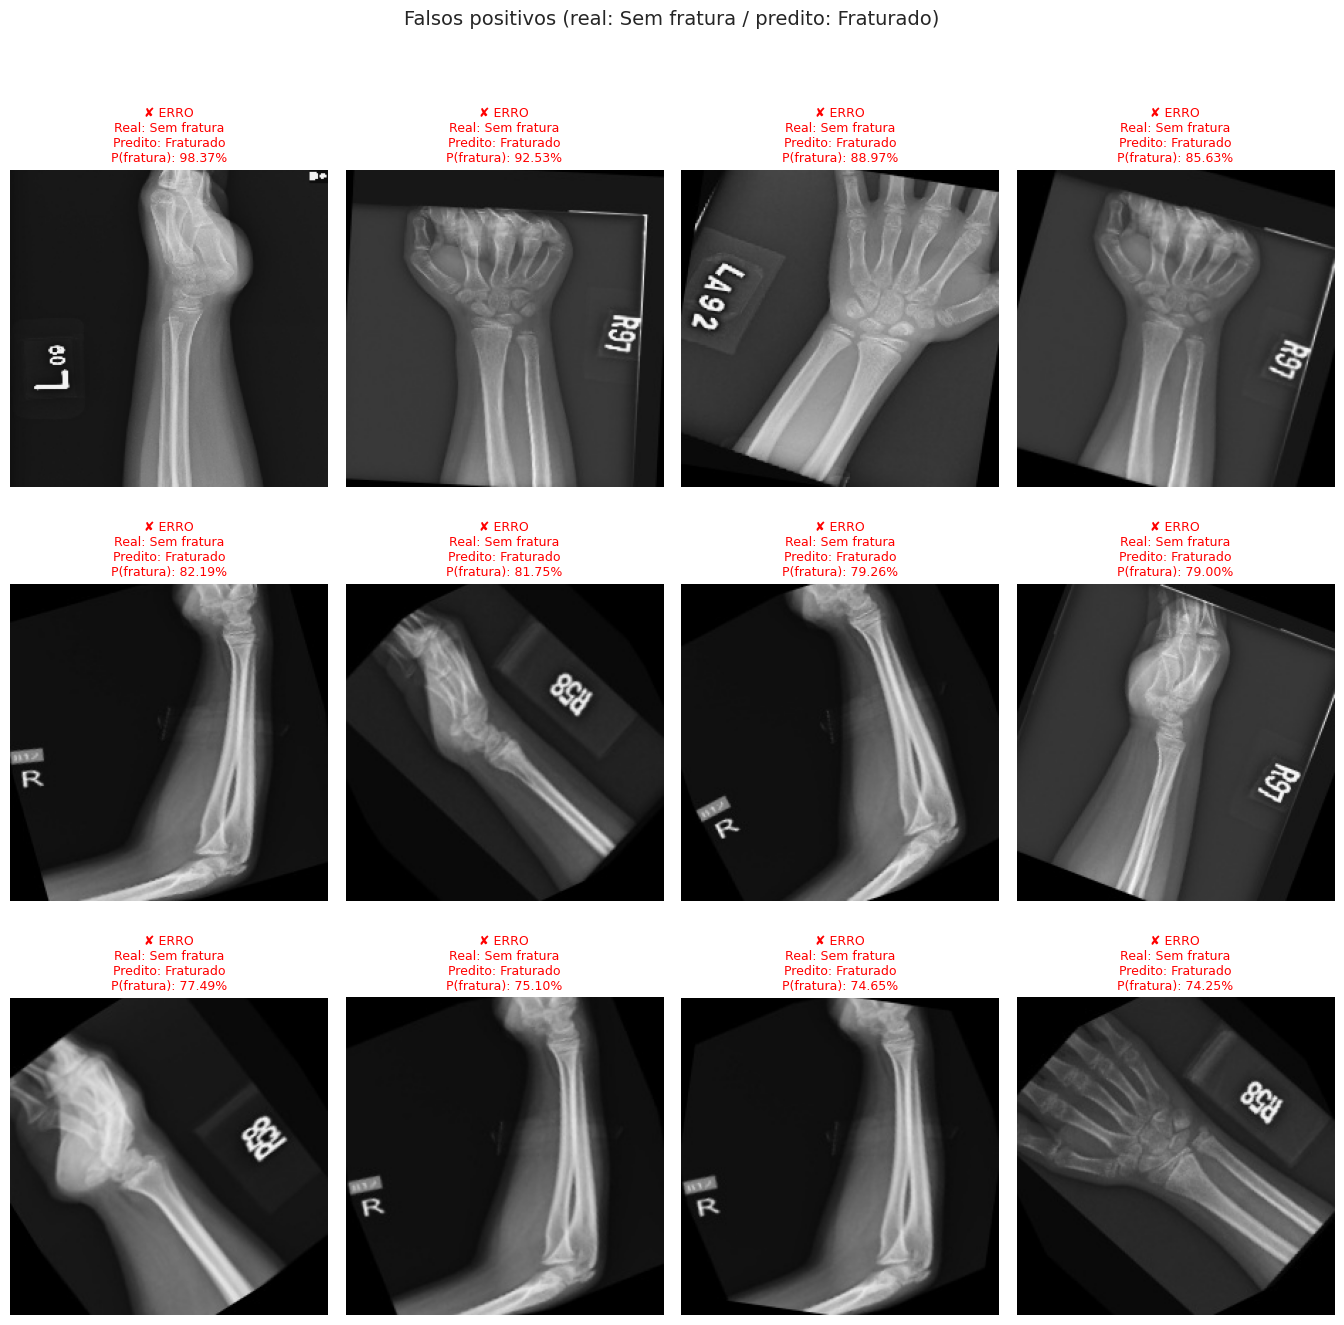

In [ ]:
falsos_positivos = df_pred[(df_pred["real"] == 0) & (df_pred["pred"] == 1)].sort_values("prob_fratura", ascending=False)

total_sem_fratura = int((df_pred["real"] == 0).sum())
print(f"Falsos positivos: {len(falsos_positivos)} de {total_sem_fratura} imagens sem fratura "
      f"({len(falsos_positivos) / max(total_sem_fratura, 1):.2%} das imagens sem fratura foram classificadas como fraturadas com THRESHOLD = {THRESHOLD})")

if len(falsos_positivos) > 0:
    print(f"P(fratura) nos falsos positivos -> mín: {falsos_positivos['prob_fratura'].min():.2%} | "
          f"mediana: {falsos_positivos['prob_fratura'].median():.2%} | máx: {falsos_positivos['prob_fratura'].max():.2%}")

mostrar_grade(falsos_positivos.head(12), "Falsos positivos (real: Sem fratura / predito: Fraturado)")

## 30. Salvamento do modelo

Salvamos o modelo treinado no Google Drive, para poder **reutilizá-lo sem treinar novamente**. O formato `.keras` guarda a **arquitetura**, os **pesos** e a configuração de compilação.

O arquivo **não guarda** informações como o `THRESHOLD`, o tamanho de imagem esperado e a ordem das classes. Por isso salvamos também um pequeno arquivo `.json` com esses metadados ao lado do modelo.

In [ ]:
import json

# ⚙️ CAMINHO PARA SALVAR O MODELO
MODEL_PATH = '/content/drive/MyDrive/modelos/cnn_fraturas.keras'

os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)

model.save(MODEL_PATH)

metadados = {
    "class_names": CLASS_NAMES,
    "display_names": DISPLAY_NAMES,
    "img_size": list(IMG_SIZE),
    "threshold": THRESHOLD,
    "observacao": "Modelo educacional/experimental. Nao usar para diagnostico medico."
}
METADATA_PATH = MODEL_PATH.replace(".keras", "_metadata.json")
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadados, f, ensure_ascii=False, indent=2)

print("Modelo salvo em:")
print(MODEL_PATH)
print(f"Tamanho: {os.path.getsize(MODEL_PATH) / 1e6:.1f} MB")
print("\nMetadados salvos em:")
print(METADATA_PATH)

Modelo salvo em:
/content/drive/MyDrive/modelos/cnn_fraturas.keras
Tamanho: 134.1 MB

Metadados salvos em:
/content/drive/MyDrive/modelos/cnn_fraturas_metadata.json


## 31. Carregamento do modelo

Em outra sessão (ou em outro notebook), basta carregar o arquivo salvo. Para verificar que o carregamento funcionou, comparamos as previsões do modelo original com as do modelo carregado **em um lote de imagens do teste**: as diferenças devem ser praticamente nulas.

In [ ]:
loaded_model = tf.keras.models.load_model(
    MODEL_PATH
)

print("Modelo carregado com sucesso.\n")

for images, _ in test_ds.take(1):
    p_original = model(images, training=False).numpy().ravel()
    p_carregado = loaded_model(images, training=False).numpy().ravel()

diferenca_max = np.max(np.abs(p_original - p_carregado))
print(f"Diferença máxima entre as previsões (original × carregado): {diferenca_max:.2e}")
print("✅ Previsões equivalentes." if diferenca_max < 1e-4 else "⚠️ Há diferenças; verifique o carregamento.")

print("\nPrimeiras 5 previsões:")
print("  original :", np.round(p_original[:5], 4))
print("  carregado:", np.round(p_carregado[:5], 4))

Modelo carregado com sucesso.

Diferença máxima entre as previsões (original × carregado): 0.00e+00
✅ Previsões equivalentes.

Primeiras 5 previsões:
  original : [0.4387 0.4636 0.1584 0.1124 0.1153]
  carregado: [0.4387 0.4636 0.1584 0.1124 0.1153]


## 32. Teste com nova imagem

Vamos usar o modelo para prever **uma imagem individual**. Informe o caminho em `NEW_IMAGE_PATH`.

Passos:

1. **Carregar** a imagem já redimensionada para `IMG_SIZE`;
2. **Converter** para array NumPy (altura × largura × 3);
3. **Adicionar a dimensão de batch** (o modelo espera `(1, altura, largura, 3)`);
4. **Prever** e aplicar o `THRESHOLD`.

> Não divida os pixels por 255: a camada `Rescaling` **já faz isso dentro do modelo**.

Se `NEW_IMAGE_PATH` não existir, o notebook usa **uma imagem do conjunto de teste apenas para demonstração**, para que a célula funcione mesmo sem você ter informado um arquivo.

Usando a imagem informada: /content/drive/MyDrive/Projeto Final/Imagens_Teste/New_Image.png


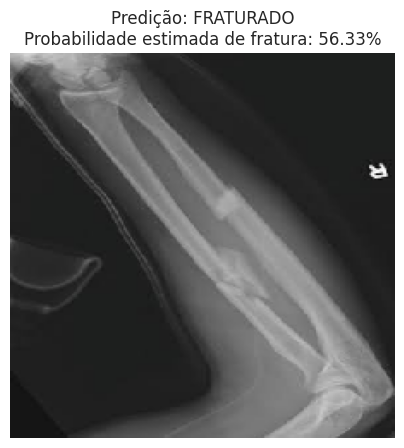

Probabilidade estimada de fratura: 56.33%
Predição: FRATURADO   (threshold = 0.5)

AVISO:
Esta previsão foi gerada por um modelo experimental de Machine Learning
e não deve ser utilizada como diagnóstico médico.


In [ ]:
# ⚙️ CAMINHO DA IMAGEM A SER TESTADA
NEW_IMAGE_PATH = '/content/drive/MyDrive/Projeto Final/Imagens_Teste/New_Image.png'

if os.path.isfile(NEW_IMAGE_PATH):
    caminho_usado = NEW_IMAGE_PATH
    print(f"Usando a imagem informada: {caminho_usado}")
else:
    caminho_usado = random.Random(SEED).choice(test_file_paths)
    print("⚠️ NEW_IMAGE_PATH não encontrado. Usando uma imagem do conjunto de teste para DEMONSTRAÇÃO:")
    print(f"   {caminho_usado}")

img = tf.keras.utils.load_img(
    caminho_usado,
    target_size=IMG_SIZE
)

img_array = tf.keras.utils.img_to_array(img)

img_array = tf.expand_dims(
    img_array,
    0
)

prediction = loaded_model.predict(img_array, verbose=0)[0][0]

classe_prevista = 1 if prediction >= THRESHOLD else 0
texto_predicao = "FRATURADO" if classe_prevista == 1 else "SEM FRATURA"

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f"Predição: {texto_predicao}\nProbabilidade estimada de fratura: {prediction:.2%}")
plt.axis("off")
plt.show()

print(f"Probabilidade estimada de fratura: {prediction:.2%}")
print(f"Predição: {texto_predicao}   (threshold = {THRESHOLD})")
print()
print("AVISO:")
print("Esta previsão foi gerada por um modelo experimental de Machine Learning")
print("e não deve ser utilizada como diagnóstico médico.")

### Como interpretar a "confiança" da previsão

Evitamos a palavra *certeza*. O valor mostrado é a **probabilidade estimada pelo modelo** — por exemplo:

```text
Probabilidade estimada de fratura: 87.4%
```

Esse número é a **saída da função sigmoid** e **não deve ser interpretado automaticamente como uma probabilidade clínica calibrada**. Redes neurais frequentemente produzem saídas **excessivamente confiantes** (perto de 0 ou 1), mesmo quando erram. Dizer que "87,4%" corresponde a 87,4% de chance real de haver fratura exigiria uma etapa específica de **calibração** e validação em dados representativos.

Além disso, o modelo só conhece o tipo de imagem que viu no treino: uma imagem de outro equipamento, outro osso ou outra projeção pode receber uma probabilidade alta ou baixa **sem nenhuma relação confiável com a realidade**.

A curva de calibração abaixo (*reliability diagram*) mostra, **no conjunto de teste**, o quanto as probabilidades do modelo coincidem com a frequência real de fraturas. Quanto mais próxima da diagonal, mais "calibradas" as probabilidades estão **naquele dataset**.

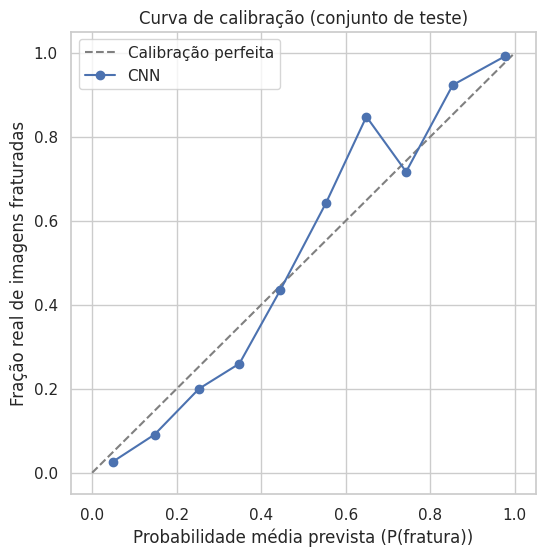

In [ ]:
from sklearn.calibration import calibration_curve

frac_positivos, prob_media = calibration_curve(
    y_true,
    y_pred_probability,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Calibração perfeita")
plt.plot(prob_media, frac_positivos, marker="o", label="CNN")
plt.title("Curva de calibração (conjunto de teste)")
plt.xlabel("Probabilidade média prevista (P(fratura))")
plt.ylabel("Fração real de imagens fraturadas")
plt.legend()
plt.show()

## 33. Transfer Learning

Até aqui construímos uma CNN **do zero**: todos os pesos começaram aleatórios e foram aprendidos apenas com as imagens deste dataset.

No **Transfer Learning**, partimos de um modelo **pré-treinado** em um dataset enorme (o *ImageNet*, com milhões de imagens de objetos do cotidiano). As camadas iniciais desses modelos já aprenderam a detectar padrões genéricos (bordas, texturas, formas) que também são úteis em outras imagens, inclusive radiografias, mesmo que o domínio seja bem diferente.

Exemplos de modelos pré-treinados: **MobileNetV2** (leve e rápido), **EfficientNet** e **ResNet**. Aqui usaremos o MobileNetV2.

```text
CNN construída do zero
  • Todos os pesos começam aleatórios
  • Arquitetura simples e didática
  • Pode precisar de mais dados e/ou mais épocas
  • Poucos parâmetros de "conhecimento prévio"

Transfer Learning
  • A base (extrator de características) já vem treinada no ImageNet
  • Treinamos apenas a "cabeça" de classificação (base congelada)
  • Costuma convergir mais rápido e com menos dados
  • Não há garantia de superar a CNN do zero em radiografias
```

### Como será a implementação

1. `MobileNetV2(include_top=False, weights='imagenet')`: carrega **apenas a base convolucional**, sem o classificador original de 1000 classes.
2. `base_model.trainable = False`: **congela** a base; seus pesos **não** serão alterados no treino inicial.
3. Adicionamos uma **cabeça de classificação binária**: `GlobalAveragePooling2D → Dropout → Dense(1, sigmoid)`.
4. O MobileNetV2 espera pixels em **[-1, 1]**; por isso usamos `Rescaling(1/127.5, offset=-1)` (no lugar do `Rescaling(1/255)` da CNN básica).

A CNN básica **não é substituída**: as duas abordagens são mantidas para comparação (seção 34). *(Uma etapa posterior, o **fine-tuning**, consiste em descongelar parte da base e treinar com learning rate bem pequeno; não é feita aqui.)*

### Parâmetros ⚙️

* `RUN_TRANSFER_LEARNING`: `True` para executar esta seção; `False` para pulá-la (as células seguintes checam esse valor).
* `TL_EPOCHS`: máximo de épocas.
* `TL_WEIGHTS`: `'imagenet'` (padrão; requer internet no Colab) ou `None` (pesos aleatórios; só para testes).

In [ ]:
# ⚙️ PARÂMETROS DO TRANSFER LEARNING
RUN_TRANSFER_LEARNING = True
TL_EPOCHS = 10
TL_WEIGHTS = 'imagenet'

if RUN_TRANSFER_LEARNING:
    base_model = tf.keras.applications.MobileNetV2(
        input_shape=(IMG_HEIGHT, IMG_WIDTH, 3),
        include_top=False,
        weights=TL_WEIGHTS
    )

    base_model.trainable = False   # congela a base pré-treinada

    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = data_augmentation(inputs)                          # só atua no treino
    x = layers.Rescaling(1./127.5, offset=-1)(x)           # pixels 0-255 -> [-1, 1] (esperado pelo MobileNetV2)
    x = base_model(x, training=False)                      # base congelada (BatchNorm em modo de inferência)
    x = layers.GlobalAveragePooling2D()(x)                 # resume cada mapa de características em 1 número
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)

    tl_model = keras.Model(inputs, outputs, name="mobilenetv2_transfer")

    tl_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss='binary_crossentropy',
        metrics=[
            'accuracy',
            tf.keras.metrics.Precision(name='precision'),
            tf.keras.metrics.Recall(name='recall')
        ]
    )

    tl_model.summary()
else:
    print("Transfer Learning desativado (RUN_TRANSFER_LEARNING = False).")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Treinamento do modelo com Transfer Learning

Usamos os **mesmos datasets**, o mesmo threshold e o mesmo tipo de Early Stopping, para que a comparação seja justa. Como só a cabeça de classificação é treinada, o treino tende a ser mais rápido por época.

Epoch 1/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 26s 75ms/step - accuracy: 0.6768 - loss: 0.5873 - precision: 0.6876 - recall: 0.6607 - val_accuracy: 0.7350 - val_loss: 0.4802 - val_precision: 0.7457 - val_recall: 0.8472
Epoch 2/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.7783 - loss: 0.4636 - precision: 0.7934 - recall: 0.7592 - val_accuracy: 0.7517 - val_loss: 0.4737 - val_precision: 0.7592 - val_recall: 0.8583
Epoch 3/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 15s 63ms/step - accuracy: 0.8110 - loss: 0.4150 - precision: 0.8237 - recall: 0.7965 - val_accuracy: 0.7400 - val_loss: 0.5149 - val_precision: 0.7179 - val_recall: 0.9333
Epoch 4/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 17s 70ms/step - accuracy: 0.8211 - loss: 0.3984 - precision: 0.8359 - recall: 0.8038 - val_accuracy: 0.7400 - val_loss: 0.4839 - val_precision: 0.7217 - val_recall: 0.9222
Epoch 5/10
236/236 ━━━━━━━━━━━━━━━━━━━━ 15s 64ms/step - accuracy: 0.8354 - loss: 0.3712 - precision: 0.8487 - recall: 0.8206 - val_accuracy: 0.7650 - va

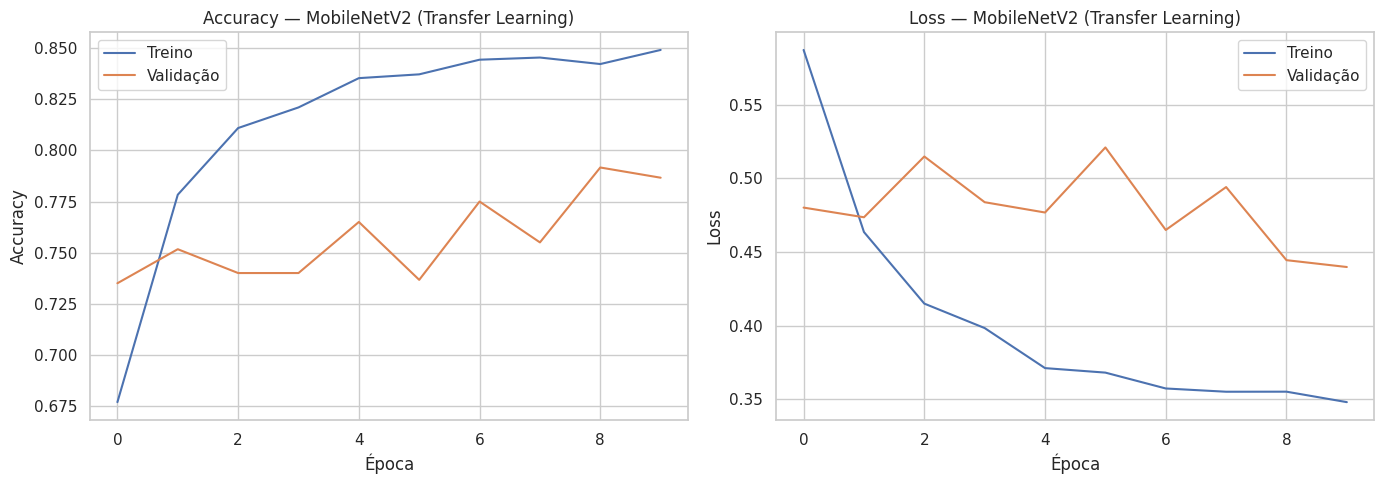

In [ ]:
if RUN_TRANSFER_LEARNING:
    early_stopping_tl = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )

    t0 = time.time()

    history_tl = tl_model.fit(
        train_ds,
        validation_data=validation_ds,
        epochs=TL_EPOCHS,
        callbacks=[early_stopping_tl],
        class_weight=class_weight
    )

    print(f"\nTreinamento (Transfer Learning) finalizado em {(time.time() - t0) / 60:.1f} min "
          f"({len(history_tl.history['loss'])} épocas executadas)")

    # Curvas de treino
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history_tl.history['accuracy'], label='Treino')
    axes[0].plot(history_tl.history['val_accuracy'], label='Validação')
    axes[0].set_title('Accuracy — MobileNetV2 (Transfer Learning)')
    axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy'); axes[0].legend()
    axes[1].plot(history_tl.history['loss'], label='Treino')
    axes[1].plot(history_tl.history['val_loss'], label='Validação')
    axes[1].set_title('Loss — MobileNetV2 (Transfer Learning)')
    axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss'); axes[1].legend()
    plt.tight_layout()
    plt.show()

### Funções para avaliar e comparar os modelos

Para não repetir o código de avaliação, criamos duas funções curtas:

* `obter_previsoes(modelo, dataset)`: percorre o dataset **lote a lote** (igual ao que fizemos na seção 18) e devolve `(y_true, probabilidades)`.
* `calcular_metricas(y_true, probabilidades, threshold)`: aplica o threshold e devolve um dicionário com **Accuracy, Precision, Recall, F1 e AUC**.

Para a CNN básica **reaproveitamos as previsões já calculadas** na seção 18 (`y_true`, `y_pred_probability`).

In [ ]:
def obter_previsoes(modelo, dataset):
    # Percorre o dataset e devolve (rótulos reais, probabilidades previstas)
    reais, probs = [], []
    for imgs, labs in dataset:
        probs.append(modelo(imgs, training=False).numpy().ravel())
        reais.append(labs.numpy().ravel())
    return np.concatenate(reais).astype(int), np.concatenate(probs)


def calcular_metricas(y_real, probabilidades, threshold):
    # Calcula as métricas de classificação para um dado threshold
    y_hat = (probabilidades >= threshold).astype(int)
    fpr_, tpr_, _ = roc_curve(y_real, probabilidades)
    return {
        "Accuracy":  accuracy_score(y_real, y_hat),
        "Precision": precision_score(y_real, y_hat, zero_division=0),
        "Recall":    recall_score(y_real, y_hat, zero_division=0),
        "F1":        f1_score(y_real, y_hat, zero_division=0),
        "AUC":       auc(fpr_, tpr_),
    }


if RUN_TRANSFER_LEARNING:
    y_true_tl, y_prob_tl = obter_previsoes(tl_model, test_ds)
    assert np.array_equal(y_true_tl, y_true), "A ordem do teste mudou entre os modelos."

    y_pred_tl = (y_prob_tl >= THRESHOLD).astype(int)
    cm_tl = confusion_matrix(y_true_tl, y_pred_tl, labels=[0, 1])

    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(cm_tl, annot=True, fmt='d', cmap='Greens',
                xticklabels=DISPLAY_NAMES, yticklabels=DISPLAY_NAMES)
    plt.title('Matriz de Confusão — MobileNetV2')
    plt.xlabel('Classe prevista'); plt.ylabel('Classe real')
    plt.show()

    print(classification_report(y_true_tl, y_pred_tl, labels=[0, 1],
                                target_names=DISPLAY_NAMES, digits=4, zero_division=0))

## 34. Comparação dos modelos

A tabela abaixo é **preenchida automaticamente** com os resultados de cada modelo no **mesmo conjunto de teste** e **mesmo threshold**. Não assumimos de antemão qual modelo terá o melhor desempenho: isso depende dos dados, dos hiperparâmetros e até da semente aleatória.

Cuidados na leitura:

* Diferenças **pequenas** entre modelos podem estar dentro da variação natural entre execuções (outra semente ou outra divisão poderia inverter a ordem).
* Compare **várias métricas**, inclusive os **False Negatives**, e não apenas a Accuracy.
* O AUC **não depende do threshold**, enquanto as demais métricas dependem.

In [ ]:
resultados = {"CNN básica": calcular_metricas(y_true, y_pred_probability, THRESHOLD)}

if RUN_TRANSFER_LEARNING:
    resultados["MobileNetV2"] = calcular_metricas(y_true_tl, y_prob_tl, THRESHOLD)

df_comp = pd.DataFrame(resultados).T
df_comp.index.name = "Modelo"

# Tabela em Markdown (formato pedido)
linhas_md = ["| Modelo | Accuracy | Precision | Recall | F1 | AUC |",
             "| ------ | -------: | --------: | -----: | --: | --: |"]
for nome, r in resultados.items():
    linhas_md.append(f"| {nome} | {r['Accuracy']:.4f} | {r['Precision']:.4f} | {r['Recall']:.4f} | {r['F1']:.4f} | {r['AUC']:.4f} |")
display(Markdown("\n".join(linhas_md)))

# Gráfico de barras
df_comp.plot(kind="bar", figsize=(10, 4.5), rot=0)
plt.title("Comparação de métricas no conjunto de teste")
plt.ylabel("Valor")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

# Curvas ROC sobrepostas
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"CNN básica (AUC = {roc_auc:.4f})")
if RUN_TRANSFER_LEARNING:
    fpr_tl, tpr_tl, _ = roc_curve(y_true_tl, y_prob_tl)
    plt.plot(fpr_tl, tpr_tl, label=f"MobileNetV2 (AUC = {auc(fpr_tl, tpr_tl):.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Chute aleatório")
plt.title("Curvas ROC — comparação")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.show()

# Leitura factual (gerada a partir dos números desta execução)
if RUN_TRANSFER_LEARNING:
    melhor_f1  = df_comp["F1"].idxmax()
    melhor_auc = df_comp["AUC"].idxmax()
    fn_cnn = int(((y_true == 1) & (y_pred == 0)).sum())
    fn_tl  = int(((y_true_tl == 1) & (y_pred_tl == 0)).sum())
    print(f"Nesta execução: maior F1 = {melhor_f1} | maior AUC = {melhor_auc}")
    print(f"Falsos negativos: CNN básica = {fn_cnn} | MobileNetV2 = {fn_tl}")
    print("Lembre-se: diferenças pequenas podem não ser significativas (uma única execução, um único teste).")

## 35. Limitações

Este projeto é educacional. Ao interpretar os resultados, considere:

* **Quantidade de imagens:** poucos exemplos limitam o que a rede consegue aprender e tornam as métricas instáveis (um pequeno teste gera estimativas com grande incerteza).
* **Balanceamento entre classes:** desbalanceamento pode inflar a Accuracy e esconder desempenho ruim na classe minoritária (seção 6).
* **Qualidade das imagens:** ruído, baixo contraste, cortes e artefatos afetam o modelo.
* **Diferenças entre equipamentos:** aparelhos, protocolos e configurações distintos geram imagens com aparências diferentes.
* **Diferentes posições dos ossos:** incidências e projeções variadas; a rede pode não generalizar para posições pouco representadas.
* **Possível viés do dataset:** se as imagens de cada classe vieram de **fontes diferentes** (hospitais, aparelhos, datasets combinados), a rede pode aprender **características da fonte** (contraste, tamanho, marcações, gesso, textos) em vez da fratura em si — e ainda assim obter métricas altas.
* **Possível duplicação ou imagens muito semelhantes:** cópias, ou várias imagens do mesmo paciente/exame distribuídas entre treino e teste, causam *data leakage* e resultados otimistas. Use `CHECK_DUPLICATES` (seção 6) para detectar duplicatas exatas; para o caso de "mesmo paciente" é preciso ter essa informação nos metadados.
* **Diferença entre treinamento e uso em imagens externas:** o desempenho medido no teste vale para imagens **parecidas com as do dataset**. Imagens de outra fonte podem ter desempenho muito pior.
* **Generalização para outros conjuntos de dados:** a única forma de saber é avaliar em um conjunto **externo** e independente.
* **Calibração e interpretabilidade:** as probabilidades da sigmoid não são calibradas clinicamente (seção 32), e os mapas de características não explicam por que o modelo decidiu como decidiu.
* **Avaliação clínica:** não houve validação por especialistas, análise de subgrupos, nem estudo prospectivo.

> Uma **Accuracy elevada no dataset não garante desempenho equivalente em imagens de outras fontes**. Este notebook **não** é um dispositivo médico e **não** deve ser usado para diagnóstico ou decisão clínica.

## 36. Conclusão

### O que foi realizado?

```text
Dataset
↓
Google Drive
↓
Pré-processamento
↓
Data Augmentation
↓
CNN
↓
Treinamento
↓
Validação
↓
Teste
↓
Predições
↓
Matriz de Confusão
↓
Precision
↓
Recall
↓
F1-Score
↓
ROC/AUC
↓
Análise dos erros
```

### Resultados obtidos nesta execução

A célula abaixo gera o resumo **a partir dos valores reais calculados durante a execução** (nenhum número foi escrito manualmente).

In [ ]:
n_treino = int(df_counts.loc["Treino", "Total"])
n_val    = int(df_counts.loc["Validação", "Total"])
n_teste  = int(df_counts.loc["Teste", "Total"])

epocas_exec = len(history.history["loss"])
acc_tr_best  = history.history["accuracy"][best_epoch]
acc_val_best = history.history["val_accuracy"][best_epoch]

texto = f"""
* **Dataset:** {n_treino} imagens de treino, {n_val} de validação e {n_teste} de teste.
  Treino: {int(df_counts.loc['Treino', DISPLAY_NAMES[0]])} '{DISPLAY_NAMES[0]}' × {int(df_counts.loc['Treino', DISPLAY_NAMES[1]])} '{DISPLAY_NAMES[1]}' ({nivel}).
* **Treinamento da CNN básica:** {epocas_exec} épocas executadas (máximo de {EPOCHS}); melhor época pela `val_loss`: {best_epoch + 1}.
  Nessa época, Accuracy de treino = {acc_tr_best:.2%} e de validação = {acc_val_best:.2%}.
* **Desempenho no teste (threshold = {THRESHOLD}):**
  Accuracy = {accuracy:.2%} | Precision = {precision:.2%} | Recall = {recall:.2%} | F1-Score = {f1:.2%} | AUC = {roc_auc:.4f} | Average Precision = {average_precision:.4f}.
* **Matriz de confusão:** TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}.
  Das {tp + fn} imagens fraturadas do teste, {fn} não foram identificadas; das {tn + fp} imagens sem fratura, {fp} foram classificadas como fraturadas.
"""

if fn > fp:
    texto += f"* **Erros:** houve mais falsos negativos ({fn}) do que falsos positivos ({fp}) com este threshold.\n"
elif fp > fn:
    texto += f"* **Erros:** houve mais falsos positivos ({fp}) do que falsos negativos ({fn}) com este threshold.\n"
else:
    texto += f"* **Erros:** falsos positivos e falsos negativos ocorreram em quantidades iguais ({fp}).\n"

if RUN_TRANSFER_LEARNING:
    r = resultados["MobileNetV2"]
    texto += (f"* **Transfer Learning (MobileNetV2):** Accuracy = {r['Accuracy']:.2%} | Precision = {r['Precision']:.2%} | "
              f"Recall = {r['Recall']:.2%} | F1-Score = {r['F1']:.2%} | AUC = {r['AUC']:.4f}.\n")

texto += (f"* **Modelo salvo em:** `{MODEL_PATH}`\n")

display(Markdown(texto))

### Considerações finais

* A **Accuracy sozinha não basta**: a análise conjunta de matriz de confusão, Precision, Recall, F1, ROC/AUC e Precision-Recall dá uma visão mais completa do comportamento do modelo.
* A **análise dos erros** (falsos negativos e falsos positivos) é o ponto de partida para melhorar o modelo: revisar rótulos, balancear classes, melhorar a qualidade dos dados, ajustar o Data Augmentation ou a arquitetura.
* Resultados obtidos **no teste deste dataset** não garantem o mesmo desempenho em imagens de outras fontes (seção 35).

### Próximos passos possíveis

* Testar outros tamanhos de imagem, arquiteturas e hiperparâmetros (usando o conjunto de **validação** para decidir);
* Usar `class_weight` se houver desbalanceamento;
* Fazer *fine-tuning* do MobileNetV2 e testar EfficientNet/ResNet;
* Repetir o treino com diferentes sementes e reportar a variação dos resultados;
* Avaliar em um **conjunto externo** independente;
* Explorar técnicas de interpretabilidade (por exemplo, Grad-CAM) e de calibração de probabilidades.

---

### ✍️ Suas observações

*Escreva aqui as suas conclusões a partir dos resultados e imagens acima.*

> ⚠️ **Lembrete final:** este é um projeto educacional/experimental. Os resultados não devem ser utilizados isoladamente para diagnóstico médico ou tomada de decisão clínica.